# Hackathon · Team 4 · ResPlan autoencoder

An autoencoder trained on **residential floor plans** from the ResPlan dataset.

**Use case:** *(write here: similarity search or anomaly detection, and who it is for)*

The training code (`show_images`, `train_autoencoder`, `reconstruct`, `reconstruction_error`, `n_params`) is copied from the class notebook `hackathon/docs/01_autoencoders.ipynb`. The two models are the class models, changed for 64×64 images.

**Contents**
0. Setup
1. The data: load, split, turn each plan into an image
2. The models
3. A first training run (test that everything works)

# 0. Setup

In [2]:
import json
import pickle
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from shapely import affinity
from sklearn.metrics import precision_score, recall_score, roc_auc_score

# Helper file from the ResPlan repository (MIT licence), copied into this folder
from resplan_utils import plot_plan, normalize_keys, get_geometries, geometry_to_mask, get_plan_width

In [3]:
# --- Folders ------------------------------------------------------------------
# This notebook is in 01_autoencoder/notebook/, so the other folders are one or two levels up.
DATA_DIR = Path("../../data")       # ResPlan.pkl and split.json (not on GitHub)
FIG_DIR = Path("../figures")        # figures for the README and the model card
MODEL_DIR = Path("../models")       # ONNX file and model card for Hugging Face
for folder in [FIG_DIR, MODEL_DIR]:
    folder.mkdir(exist_ok=True)

pd.set_option("display.float_format", "{:,.4f}".format)
plt.rcParams["figure.figsize"] = (10, 5)

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print(f"PyTorch {torch.__version__}, using device: {DEVICE}")


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

PyTorch 2.15.0+cpu, using device: cpu


# 1. The data

### Dataset card
| | |
|---|---|
| **Name** | ResPlan: a vector-graph dataset of 17,000 residential floor plans |
| **Source** | https://github.com/dariabasha/ResPlan (fork of the ResPlan release) |
| **Licence** | Data: CC BY 4.0. Code (`resplan_utils.py`): MIT |
| **Content** | One floor per plan: polygons for walls, doors, windows and rooms (bedroom, kitchen, bathroom, ...) |
| **Splits** | `split.json`: 13,053 train / 1,632 validation / 1,632 test, plus 683 augmented copies |
| **Limits** | All plans come from South Asian housing markets. About 7% are near-duplicates. |

**How to get the data:** download `ResPlan.zip` and `split.json` from the repository above, unzip, and put `ResPlan.pkl` and `split.json` in the `data/` folder at the root of this repository.

In [5]:
with open(DATA_DIR / "ResPlan.pkl", "rb") as f:
    plans = pickle.load(f)
for p in plans:
    normalize_keys(p)          # fixes a typo in some plans: "balacony" -> "balcony"

print(f"{len(plans):,} plans loaded")
print("keys of one plan:", sorted(plans[0].keys()))

17,000 plans loaded
keys of one plan: ['area', 'balcony', 'bathroom', 'bedroom', 'door', 'front_door', 'garden', 'id', 'inner', 'kitchen', 'land', 'living', 'neighbor', 'net_area', 'parking', 'pool', 'wall', 'wall_depth', 'window']


# 1b. Data cleaning

In [24]:
splits = json.loads((DATA_DIR / "split.json").read_text())
split_of_id = {int(i): name for name, ids in splits.items() for i in ids}

LAYERS = ["inner", "wall", "door", "window", "front_door", "living", "bedroom", "bathroom",
          "kitchen", "balcony", "storage", "stair", "garden", "parking", "pool", "veranda", "land"]
ROOM_LAYERS = ["living", "bedroom", "bathroom", "kitchen", "balcony", "storage", "stair"]


def describe_plan(i, plan):
    # One row per plan: how many polygons each layer has, and the area of every room type
    footprint = get_geometries(plan.get("inner"))
    row = {"index": i, "id": int(plan["id"]), "split": split_of_id.get(int(plan["id"]), "none"),
           "area_m2": float(plan["area"]),
           "footprint_parts": len(footprint),
           "footprint_px": sum(g.area for g in footprint)}
    for layer in LAYERS:
        parts = get_geometries(plan.get(layer))
        row[f"n_{layer}"] = len(parts)
        if layer in ROOM_LAYERS:
            row[f"px_{layer}"] = sum(g.area for g in parts)
    corners = [len(g.exterior.coords) for r in ROOM_LAYERS for g in get_geometries(plan.get(r))
               if hasattr(g, "exterior")]
    row["max_corners"] = max(corners, default=0)       # the most corners of any single room
    return row


table = pd.DataFrame([describe_plan(i, p) for i, p in enumerate(plans)])

# We collect every problem in one column. "" = no problem, the plan stays.
table["remove_reason"] = ""


def flag(mask, reason):
    # Write the reason only where no earlier step has flagged the plan yet
    new = mask & (table["remove_reason"] == "")
    table.loc[new, "remove_reason"] = reason
    print(f"{reason:45s} {new.sum():6,} plans flagged")


print(f"{len(table):,} plans, {table.shape[1]} columns")
print(table["split"].value_counts())
table.head()

17,000 plans, 32 columns
split
train        13053
val           1632
test          1632
augmented      683
Name: count, dtype: int64


,index,id,split,area_m2,footprint_parts,footprint_px,n_inner,n_wall,n_door,n_window,...,px_storage,n_stair,px_stair,n_garden,n_parking,n_pool,n_veranda,n_land,max_corners,remove_reason
0,0,14433,train,120.7739,1,"46,029.2856",1,10,8,7,...,0.0000,0,0.0000,0,0,0,0,1,18,
1,1,14926,train,84.5417,1,"43,837.3977",1,7,5,5,...,0.0000,0,0.0000,0,0,0,0,1,20,
2,2,14877,train,160.5364,1,"29,698.6159",1,11,7,9,...,0.0000,0,0.0000,0,0,0,0,1,18,
3,3,17054,val,124.4900,1,"43,489.5382",1,7,5,5,...,0.0000,0,0.0000,0,0,0,0,2,23,
4,4,5410,train,92.9030,1,"40,562.0155",1,10,7,8,...,0.0000,0,0.0000,0,0,0,0,3,19,


In [25]:
# 1) Exact duplicates: is every id different?
print(f"Is 'id' unique? {table['id'].is_unique}")

# 2) The 683 augmented plans are rotated / flipped / scaled copies made on purpose
flag(table["split"] == "augmented", "augmented copy")

# 3) Hidden duplicates: the same flat published twice, sometimes rotated or mirrored.
#    Rotating or mirroring a plan does not change its sizes, so we compare a "fingerprint":
#    the number of rooms of each type, the % of the footprint each room type takes, and the size.
fp = table[[f"n_{r}" for r in ["living", "bedroom", "bathroom", "kitchen", "balcony", "wall", "door", "window"]]].copy()
for r in ["living", "bedroom", "bathroom", "kitchen"]:
    fp[f"pct_{r}"] = (table[f"px_{r}"] / table["footprint_px"] * 100).round(0)
fp["area_m2"] = table["area_m2"].round(0)
table["fingerprint"] = fp.astype(str).agg("|".join, axis=1)

originals = table[table["split"] != "augmented"]
in_group = originals.duplicated("fingerprint", keep=False)
print(f"Original plans that have a twin: {in_group.sum():,}")

# Leakage check: a test or validation plan whose twin is in the training set
train_fps = set(originals.loc[originals["split"] == "train", "fingerprint"])
for name in ["val", "test"]:
    leak = (originals["split"] == name) & originals["fingerprint"].isin(train_fps)
    print(f"{name:5s} plans with a twin in train: {leak.sum()}")

Is 'id' unique? True
augmented copy                                   683 plans flagged
Original plans that have a twin: 219
val   plans with a twin in train: 19
test  plans with a twin in train: 14


Figure saved to ..\figures\20_duplicate_twins.png


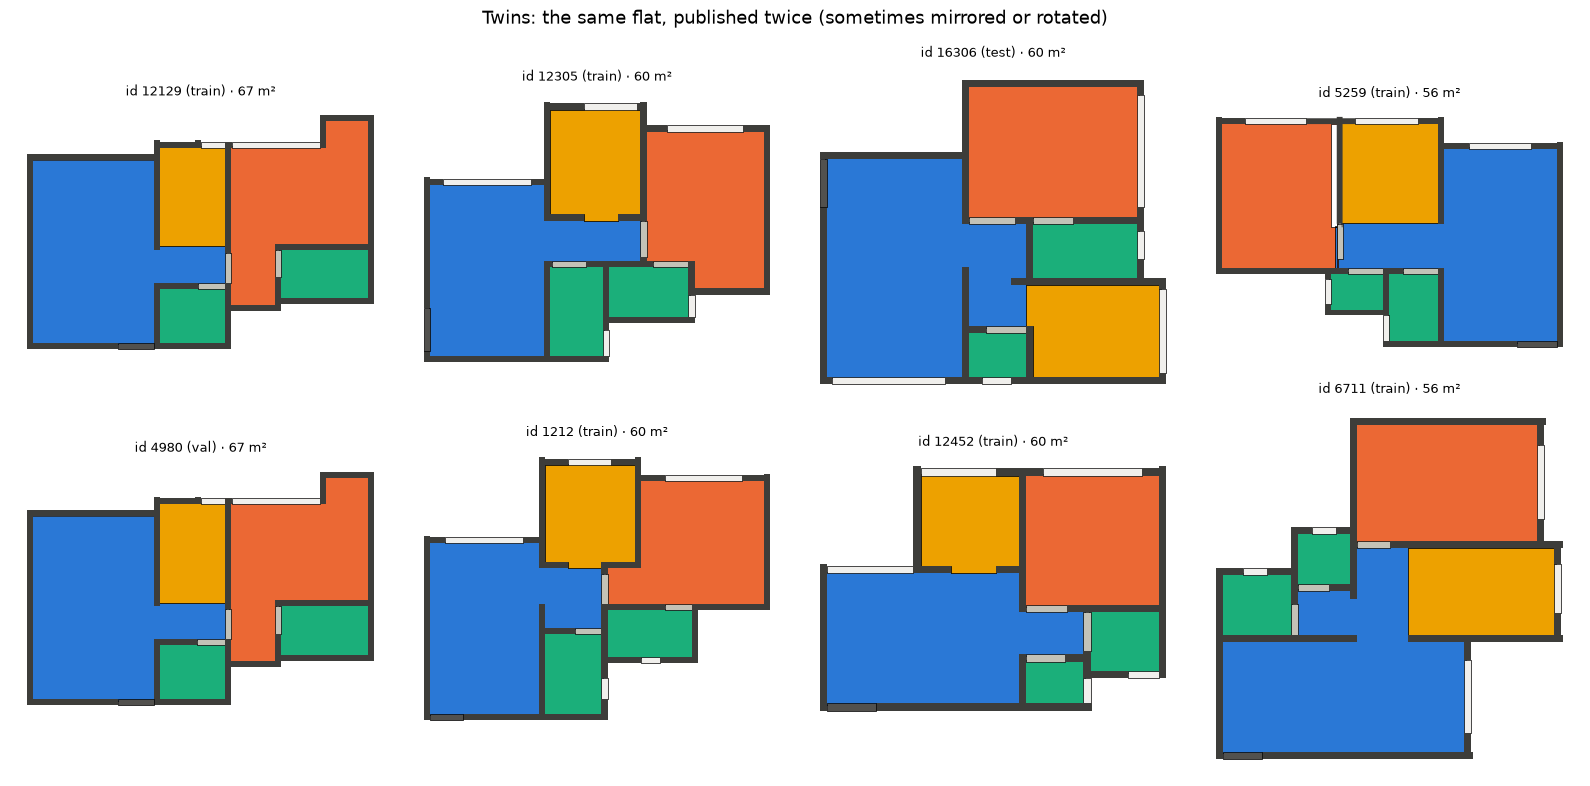

In [26]:
groups = originals[in_group].groupby("fingerprint")
examples = [g for _, g in groups][:4]
fig, axes = plt.subplots(2, len(examples), figsize=(4 * len(examples), 8))
for c, g in enumerate(examples):
    for r in range(2):
        row = g.iloc[r]
        plot_plan(plans[int(row["index"])], ax=axes[r, c], legend=False, tight=False)
        axes[r, c].set_title(f"id {row['id']} ({row['split']}) · {row['area_m2']:.0f} m²", fontsize=9)
fig.suptitle("Twins: the same flat, published twice (sometimes mirrored or rotated)", fontsize=13)
plt.tight_layout()
save_fig("20_duplicate_twins")
plt.show()

### Split first
We use the **canonical split** of the dataset (`split.json`), before we do anything else. The split file lists plan ids.

We **leave out the 683 augmented plans**: they are rotated or flipped copies of other plans. If a copy of a training plan were in the test set, the test error would look better than it really is.

In [6]:
splits = json.loads((DATA_DIR / "split.json").read_text())


def as_key(x):
    # ids can be stored as numbers or as text; compare them the same way
    try:
        return int(x)
    except (TypeError, ValueError):
        return str(x)


id_to_index = {as_key(p.get("id", i)): i for i, p in enumerate(plans)}


def indices_for(name):
    ids = [as_key(i) for i in splits[name]]
    found = [id_to_index[i] for i in ids if i in id_to_index]
    print(f"{name:6s}: {len(ids):6,} ids in split.json, {len(found):6,} found in ResPlan.pkl")
    return found


train_idx = indices_for("train")
val_idx = indices_for("val")
test_idx = indices_for("test")
assert not set(train_idx) & set(test_idx), "a plan is in both train and test"

train : 13,053 ids in split.json, 13,053 found in ResPlan.pkl
val   :  1,632 ids in split.json,  1,632 found in ResPlan.pkl
test  :  1,632 ids in split.json,  1,632 found in ResPlan.pkl


### Data exploration: what kinds of apartments are in ResPlan?
The dataset has no "apartment type" label (`unitType` is empty), so we group the plans by **number of bedrooms**. We look only at the original plans (no augmented copies).

In [16]:
split_of_id = {as_key(i): name for name, ids in splits.items() for i in ids}
SPACES = ["bedroom", "bathroom", "kitchen", "living", "balcony", "storage", "stair", "garden", "parking"]

rows = []
for i, p in enumerate(plans):
    pid = as_key(p.get("id", i))
    row = {"index": i, "id": pid, "split": split_of_id.get(pid, "none"),
           "area_m2": float(p["area"]) if p.get("area") is not None else np.nan}
    for s in SPACES:
        row[f"n_{s}"] = len(get_geometries(p.get(s)))   # how many rooms of this type
    rows.append(row)

info = pd.DataFrame(rows)
info = info[(info["split"] != "augmented") & (info["n_bedroom"] > 0)]   # originals only; 3 plans have 0 bedrooms
info["bedrooms"] = info["n_bedroom"].clip(upper=6).astype(str).replace("6", "6+")
print(f"{len(info):,} original plans")
info.describe().round(1)

16,314 original plans


,index,id,area_m2,n_bedroom,n_bathroom,n_kitchen,n_living,n_balcony,n_storage,n_stair,n_garden,n_parking
count,"16,314.0000","16,314.0000","16,314.0000","16,314.0000","16,314.0000","16,314.0000","16,314.0000","16,314.0000","16,314.0000","16,314.0000","16,314.0000","16,314.0000"
mean,"8,509.9000","8,497.1000",120.6000,2.4000,2.4000,1.0000,1.0000,1.3000,0.1000,0.0000,0.1000,0.0000
std,"4,911.1000","4,919.8000",55.0000,0.8000,0.7000,0.1000,0.1000,1.0000,0.3000,0.2000,0.3000,0.1000
min,0.0000,0.0000,0.1000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,"4,257.2000","4,258.2000",87.1000,2.0000,2.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000
50%,"8,519.5000","8,491.5000",109.6000,2.0000,2.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000
75%,"12,764.8000","12,759.8000",140.7000,3.0000,3.0000,1.0000,1.0000,2.0000,0.0000,0.0000,0.0000,0.0000
max,"16,999.0000","17,106.0000",712.9000,7.0000,7.0000,3.0000,4.0000,9.0000,3.0000,3.0000,6.0000,3.0000


Figure saved to ..\figures\00_data_overview.png


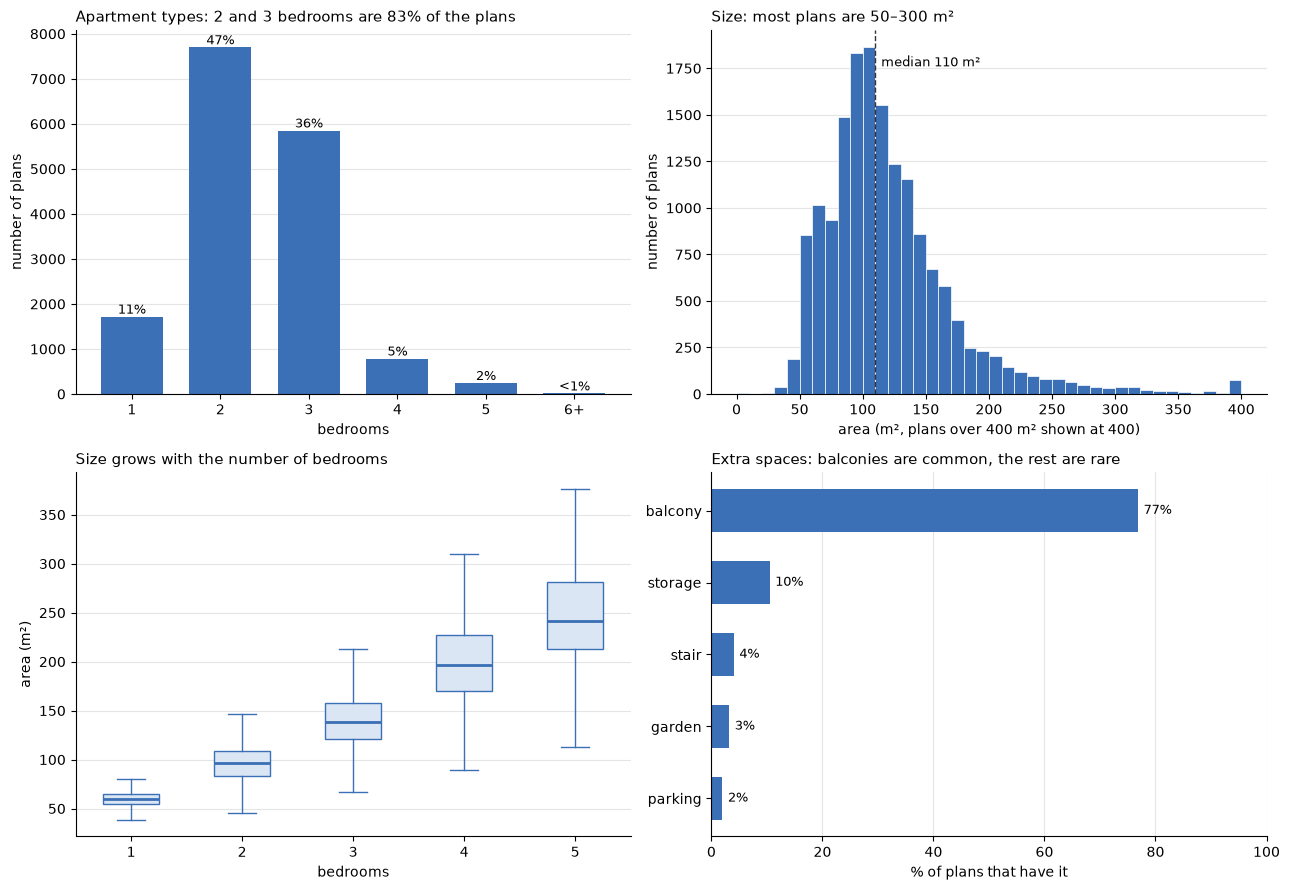

In [17]:
BLUE = "#3B6FB6"   # one colour: every chart shows a single series


def style(ax, title):
    ax.set_title(title, fontsize=11, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1) Apartment types by bedroom count
counts = info["bedrooms"].value_counts().reindex(["1", "2", "3", "4", "5", "6+"], fill_value=0)
ax = axes[0, 0]
ax.bar(counts.index, counts.values, color=BLUE, width=0.7)
for x, v in zip(counts.index, counts.values):
    share = v / len(info)
    ax.text(x, v, f"{share:.0%}" if share >= 0.01 else "<1%", ha="center", va="bottom", fontsize=9)
ax.set_xlabel("bedrooms"); ax.set_ylabel("number of plans")
style(ax, "Apartment types: 2 and 3 bedrooms are 83% of the plans")

# 2) Size in m²
ax = axes[0, 1]
ax.hist(info["area_m2"].clip(upper=400), bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
med = info["area_m2"].median()
ax.axvline(med, color="#333333", linestyle="--", linewidth=1)
ax.text(med + 5, ax.get_ylim()[1] * 0.9, f"median {med:.0f} m²", fontsize=9)
ax.set_xlabel("area (m², plans over 400 m² shown at 400)"); ax.set_ylabel("number of plans")
style(ax, "Size: most plans are 50–300 m²")

# 3) Size by apartment type
ax = axes[1, 0]
types = ["1", "2", "3", "4", "5"]
ax.boxplot([info.loc[info["bedrooms"] == t, "area_m2"] for t in types], tick_labels=types,
           showfliers=False, widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#dbe6f5", color=BLUE), medianprops=dict(color=BLUE, linewidth=2),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
ax.set_xlabel("bedrooms"); ax.set_ylabel("area (m²)")
style(ax, "Size grows with the number of bedrooms")

# 4) Extra spaces
ax = axes[1, 1]
extras = ["balcony", "storage", "stair", "garden", "parking"]
share = pd.Series({s: (info[f"n_{s}"] > 0).mean() * 100 for s in extras}).sort_values()
ax.barh(share.index, share.values, color=BLUE, height=0.6)
for y, v in zip(share.index, share.values):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlabel("% of plans that have it"); ax.set_xlim(0, 100)
style(ax, "Extra spaces: balconies are common, the rest are rare")
ax.grid(axis="y", visible=False); ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)

plt.tight_layout()
save_fig("00_data_overview")
plt.show()

Figure saved to ..\figures\00_bedrooms_vs_bathrooms.png


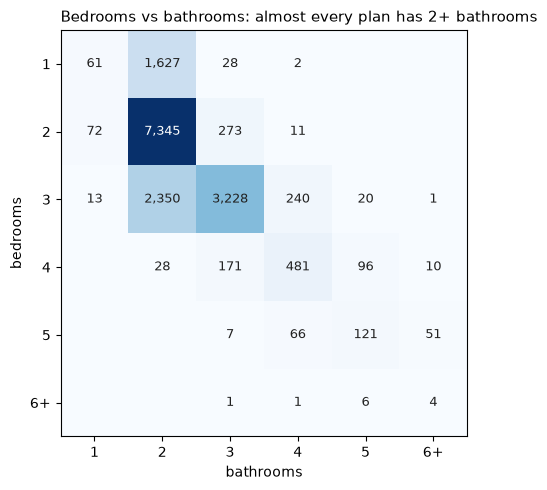

In [18]:
table = pd.crosstab(info["n_bedroom"].clip(1, 6), info["n_bathroom"].clip(1, 6))
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(table.values, cmap="Blues")
for r in range(table.shape[0]):
    for c in range(table.shape[1]):
        v = table.values[r, c]
        if v > 0:
            ax.text(c, r, f"{v:,}", ha="center", va="center", fontsize=9,
                    color="white" if v > table.values.max() / 2 else "#222222")
ax.set_xticks(range(table.shape[1]), [str(c) if c < 6 else "6+" for c in table.columns])
ax.set_yticks(range(table.shape[0]), [str(r) if r < 6 else "6+" for r in table.index])
ax.set_xlabel("bathrooms"); ax.set_ylabel("bedrooms")
ax.set_title("Bedrooms vs bathrooms: almost every plan has 2+ bathrooms", fontsize=11, loc="left")
plt.tight_layout()
save_fig("00_bedrooms_vs_bathrooms")
plt.show()

In [19]:
(pd.crosstab(info["split"], info["bedrooms"], normalize="index") * 100).round(1)

bedrooms,1,2,3,4,5,6+
split,,,,,,
test,10.5000,47.1000,36.5000,4.5000,1.5000,0.0000
train,10.5000,47.2000,35.7000,4.9000,1.5000,0.1000
val,10.6000,47.3000,36.3000,4.3000,1.4000,0.1000


no kitchen                 117 plans
1 bedroom, over 300 m²      32 plans
under 30 m²                  9 plans
Figure saved to ..\figures\00_unusual_plans.png


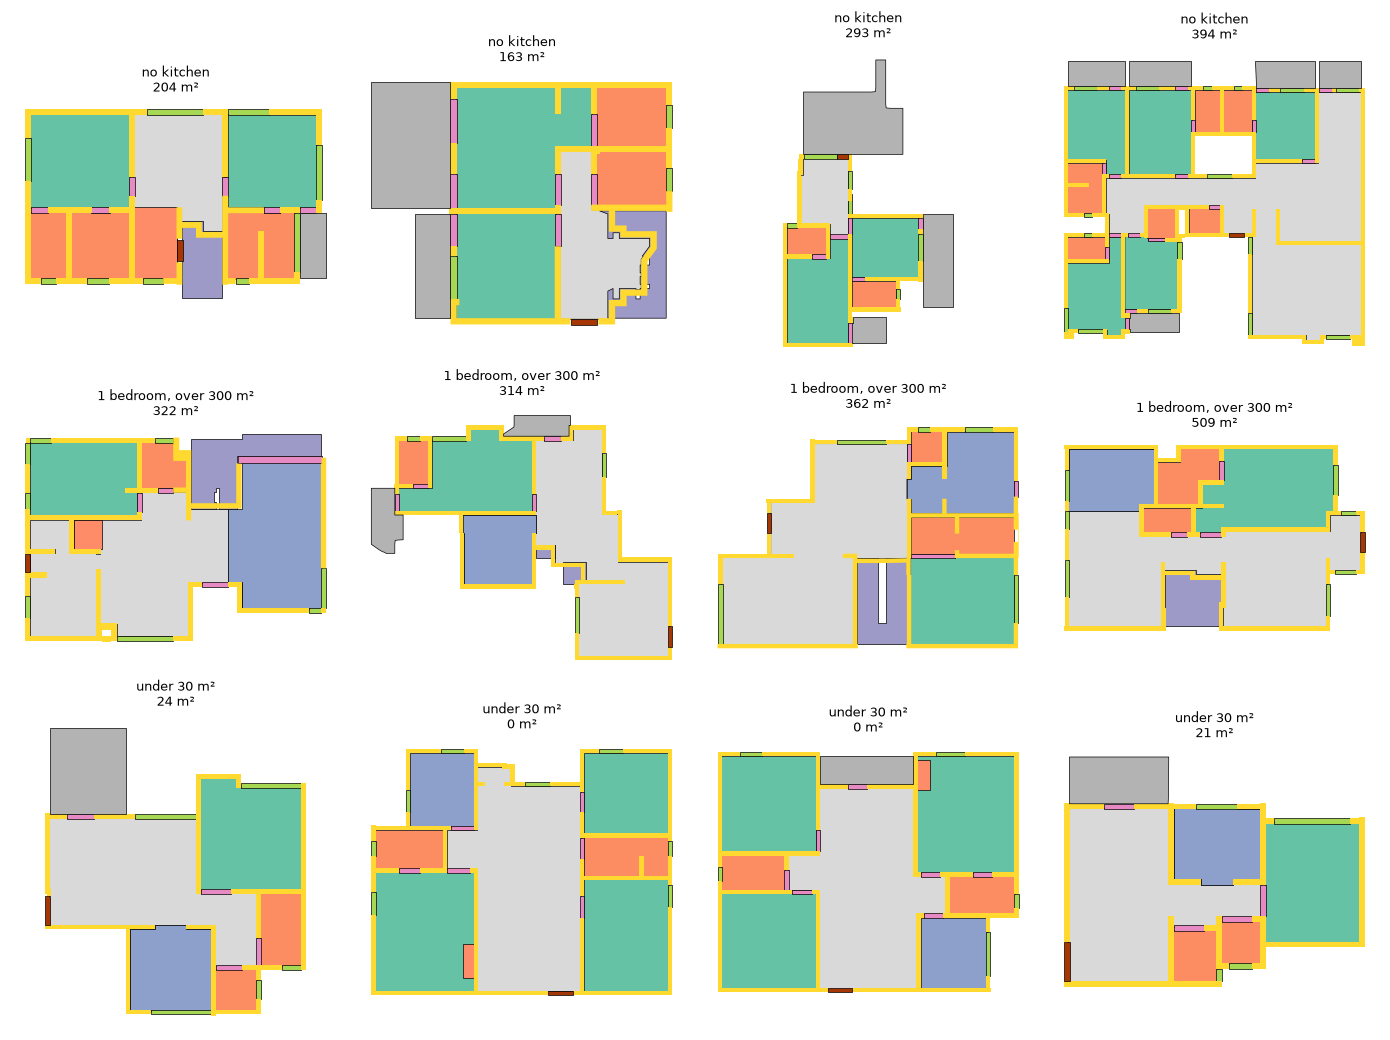

In [20]:
odd = {
    "no kitchen": info[info["n_kitchen"] == 0],
    "1 bedroom, over 300 m²": info[(info["n_bedroom"] == 1) & (info["area_m2"] > 300)],
    "under 30 m²": info[info["area_m2"] < 30],
}
for name, group in odd.items():
    print(f"{name:25s} {len(group):4d} plans")

fig, axes = plt.subplots(len(odd), 4, figsize=(14, 3.5 * len(odd)))
for r, (name, group) in enumerate(odd.items()):
    for c in range(4):
        ax = axes[r, c]
        if c < len(group):
            row = group.iloc[c]
            plot_plan(plans[int(row["index"])], ax=ax, legend=False, tight=False)
            ax.set_title(f"{name}\n{row['area_m2']:.0f} m²", fontsize=9)
        else:
            ax.axis("off")
plt.tight_layout()
save_fig("00_unusual_plans")
plt.show()

In [21]:
import resplan_utils
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from resplan_utils import plan_to_graph

# Colour-blind-safe palette (checked with a validator), always in this order.
ROOM_COLORS = {
    "living":   "#2a78d6",   # blue
    "bedroom":  "#eb6834",   # orange
    "bathroom": "#1baf7a",   # aqua
    "kitchen":  "#eda100",   # yellow
    "balcony":  "#e87ba4",   # magenta
    "storage":  "#008300",   # green
    "stair":    "#6250d6",   # violet
}
ROOMS = list(ROOM_COLORS)
NEUTRALS = {"wall": "#3d3d3a", "door": "#c3c2b7", "window": "#f0efec", "front_door": "#52514e"}

# plot_plan uses resplan_utils.CATEGORY_COLORS by default: update it, so all plans use our colours
resplan_utils.CATEGORY_COLORS.update({**ROOM_COLORS, **NEUTRALS})

room_legend = [Patch(facecolor=c, label=r) for r, c in ROOM_COLORS.items()]

Figure saved to ..\figures\00_typical_plans.png


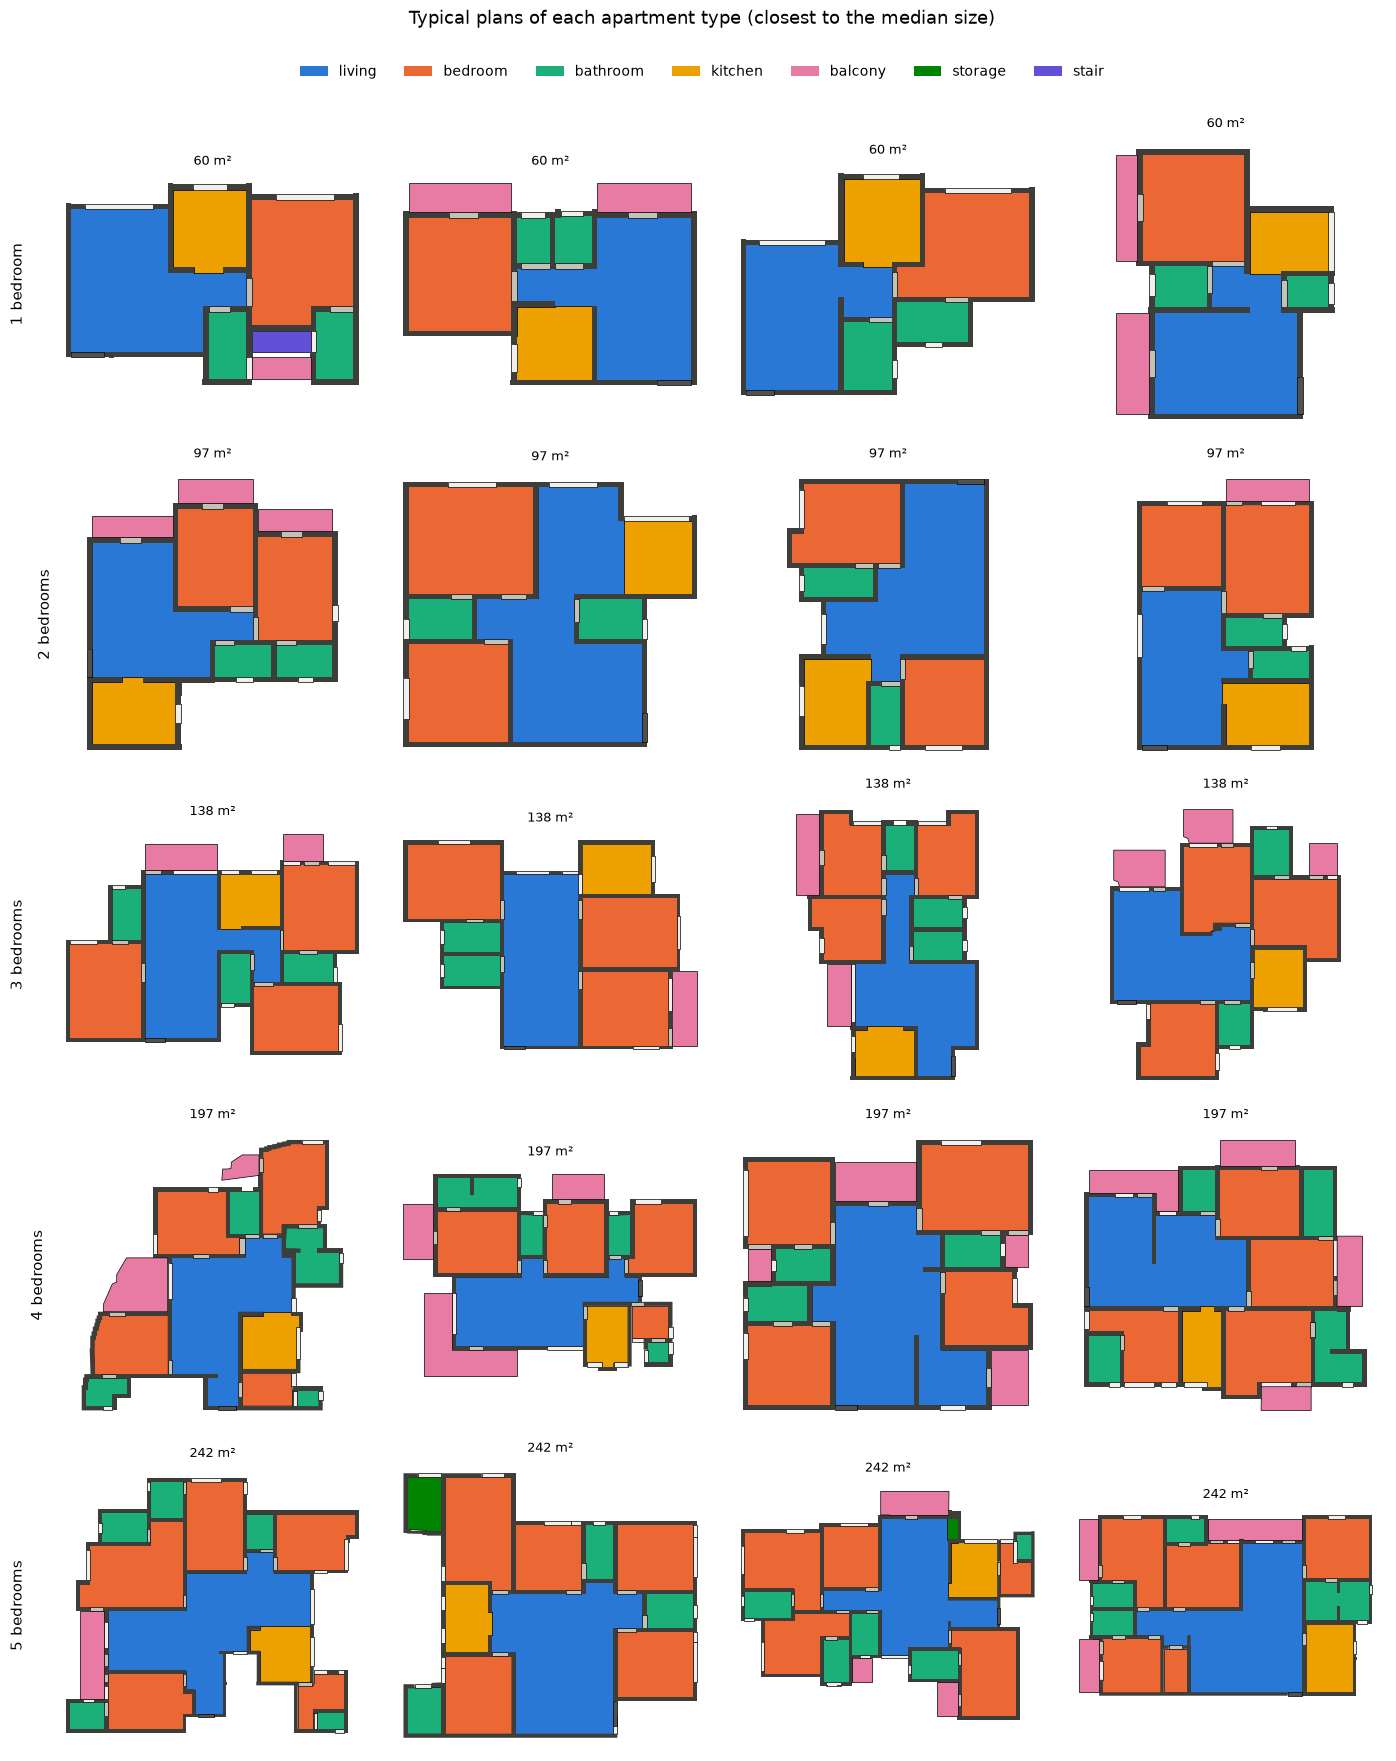

In [22]:
types = ["1", "2", "3", "4", "5"]
per_row = 4
fig, axes = plt.subplots(len(types), per_row, figsize=(14, 3.4 * len(types)))
for r, t in enumerate(types):
    group = info[info["bedrooms"] == t]
    med = group["area_m2"].median()
    closest = np.argsort(np.abs(group["area_m2"].to_numpy() - med))[:per_row]      # closest to the median size
    typical = group.iloc[closest]
    for c in range(per_row):
        ax = axes[r, c]
        row = typical.iloc[c]
        plot_plan(plans[int(row["index"])], ax=ax, legend=False, tight=False)
        ax.set_title(f"{row['area_m2']:.0f} m²", fontsize=9)
    axes[r, 0].text(-0.08, 0.5, f"{t} bedroom{'s' if t != '1' else ''}", transform=axes[r, 0].transAxes,
                    rotation=90, ha="right", va="center", fontsize=11)
fig.legend(handles=room_legend, loc="upper center", ncol=len(room_legend), frameon=False, bbox_to_anchor=(0.5, 1.01))
fig.suptitle("Typical plans of each apartment type (closest to the median size)", y=1.035, fontsize=13)
plt.tight_layout()
save_fig("00_typical_plans")
plt.show()

### From vector plan to image
An autoencoder needs inputs of the **same size**. ResPlan plans are polygons of different sizes, so we draw each plan as a **64×64 greyscale image**:

- **Scale:** each plan is scaled to fit the image (5% margin) and centred. The aspect ratio is kept. *Decision: the model sees the **shape** of the layout, not its real size in m².*
- **What we draw:** the floor area (`inner`) in grey (0.4) and the walls in white (1.0). Background is black (0). *Room types are not drawn in this first version.*
- **Why draw at 256 px first:** walls are thin. At 64 px many walls are less than one pixel wide and would disappear. We draw at 256 px and then shrink to 64 px with `INTER_AREA`, which averages the pixels, so thin walls become light grey lines instead of vanishing.
- The y axis is flipped so the image looks the same as `plot_plan` (north up).

In [7]:
IMG_SIZE = 64        # final image size (pixels)
DRAW_SIZE = 256      # we draw big first, then shrink
MARGIN = 0.05        # empty border around the plan
FLOOR_VALUE = 0.4    # grey value of the floor area
WALL_VALUE = 1.0     # grey value of the walls


def plan_to_image(plan, size=IMG_SIZE, draw_size=DRAW_SIZE, margin=MARGIN):
    floor_parts = get_geometries(plan.get("inner"))
    wall_parts = get_geometries(plan.get("wall"))
    parts = floor_parts + wall_parts
    if not parts:
        return np.zeros((size, size), dtype=np.float32)

    # bounding box of everything we draw
    minx = min(g.bounds[0] for g in parts)
    miny = min(g.bounds[1] for g in parts)
    maxx = max(g.bounds[2] for g in parts)
    maxy = max(g.bounds[3] for g in parts)
    w, h = maxx - minx, maxy - miny
    scale = draw_size * (1 - 2 * margin) / max(w, h)

    # x_img = scale * x + xoff ;  y_img = -scale * y + yoff  (the minus flips the y axis)
    xoff = (draw_size - w * scale) / 2 - minx * scale
    yoff = (draw_size + h * scale) / 2 + miny * scale

    def to_canvas(geoms):
        return [affinity.affine_transform(g, [scale, 0, 0, -scale, xoff, yoff]) for g in geoms]

    shape = (draw_size, draw_size)
    floor = geometry_to_mask(to_canvas(floor_parts), shape=shape)
    walls = geometry_to_mask(to_canvas(wall_parts), shape=shape)

    canvas = np.zeros(shape, dtype=np.float32)
    canvas[floor > 0] = FLOOR_VALUE
    canvas[walls > 0] = WALL_VALUE
    return cv2.resize(canvas, (size, size), interpolation=cv2.INTER_AREA)

Check: the original plan (top) and the image the model will see (bottom).

Figure saved to ..\figures\01_plan_to_image.png


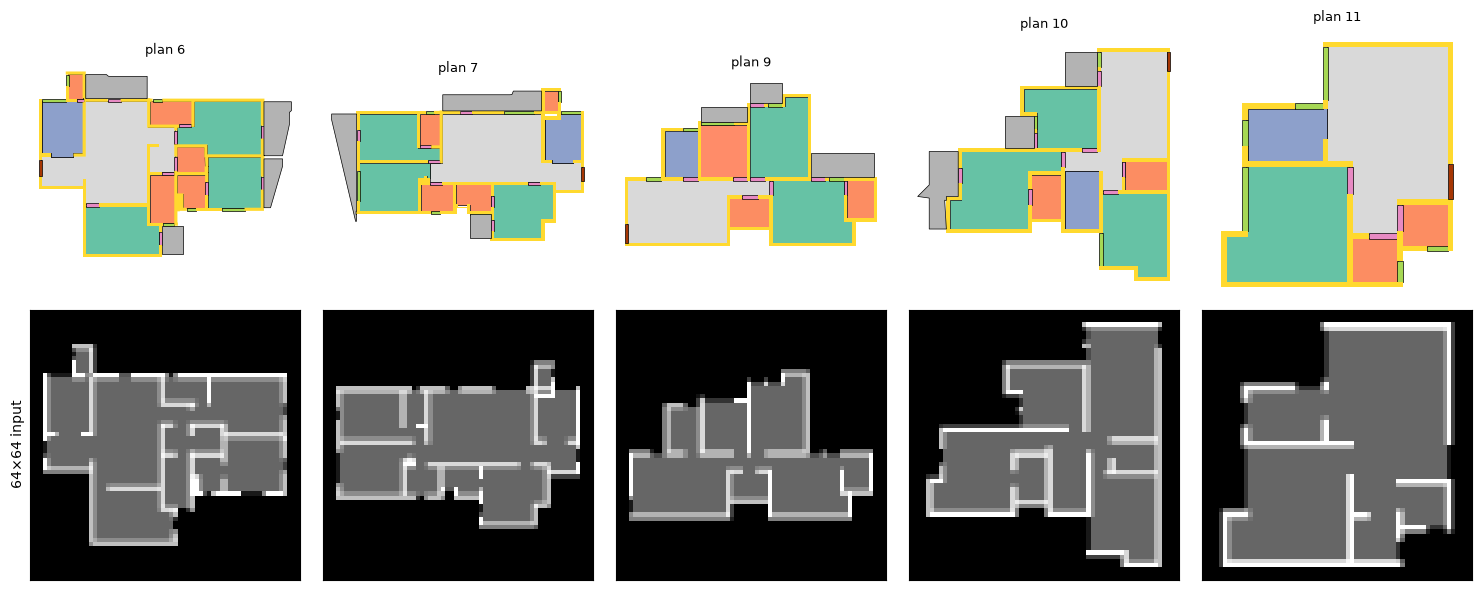

In [8]:
examples = [train_idx[k] for k in [0, 1, 2, 3, 4]]
fig, axes = plt.subplots(2, len(examples), figsize=(3 * len(examples), 6))
for c, i in enumerate(examples):
    plot_plan(plans[i], ax=axes[0, c], legend=False, tight=False)
    axes[0, c].set_title(f"plan {plans[i].get('id', i)}", fontsize=9)
    axes[1, c].imshow(plan_to_image(plans[i]), cmap="gray", vmin=0, vmax=1)
    axes[1, c].set_xticks([]); axes[1, c].set_yticks([])
axes[1, 0].set_ylabel(f"{IMG_SIZE}×{IMG_SIZE} input")
plt.tight_layout()
save_fig("01_plan_to_image")
plt.show()

### Build the three sets
Drawing 15,000 plans takes a few minutes, so we save the result in `data/` (this folder is not on GitHub). **If you change `plan_to_image`, delete the file `data/resplan_64px.npz`** so it is drawn again.

In [27]:
CACHE = DATA_DIR / f"resplan_{IMG_SIZE}px.npz"


def build_images(indices):
    return np.stack([plan_to_image(plans[i]) for i in indices]).astype(np.float32)


if CACHE.exists():
    cached = np.load(CACHE)
    X_train_np, X_val_np, X_test_np = cached["train"], cached["val"], cached["test"]
    print(f"loaded images from {CACHE}")
else:
    start = time.time()
    X_train_np, X_val_np, X_test_np = build_images(train_idx), build_images(val_idx), build_images(test_idx)
    np.savez_compressed(CACHE, train=X_train_np, val=X_val_np, test=X_test_np)
    print(f"drew {len(X_train_np) + len(X_val_np) + len(X_test_np):,} images in {time.time() - start:.0f} s, saved to {CACHE}")

# Shape (N, 1, 64, 64): (images, channels, height, width), values 0–1, as in the class notebook
X_train = torch.from_numpy(X_train_np).unsqueeze(1)
X_val = torch.from_numpy(X_val_np).unsqueeze(1)
X_test = torch.from_numpy(X_test_np).unsqueeze(1)
print("train", tuple(X_train.shape), "| validation", tuple(X_val.shape), "| test", tuple(X_test.shape))
print(f"pixel values from {X_train.min():.2f} to {X_train.max():.2f}")

loaded images from ..\..\data\resplan_64px.npz
train (13053, 1, 64, 64) | validation (1632, 1, 64, 64) | test (1632, 1, 64, 64)
pixel values from 0.00 to 1.00


Figure saved to ..\figures\02_train_samples.png


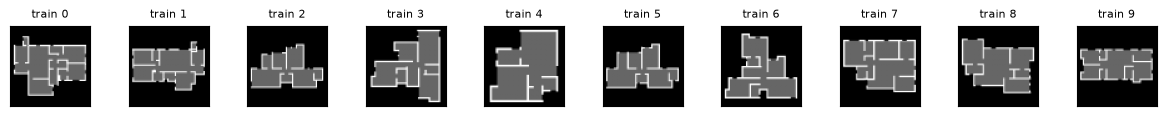

In [28]:
# Copied from the class notebook (section 1)
def show_images(rows, titles=None, row_labels=None, size=1.2):
    # rows: a list of image batches (N, 1, H, W); one row of the figure per batch
    n_rows, n_cols = len(rows), len(rows[0])
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols, size * n_rows), squeeze=False)
    for r, batch in enumerate(rows):
        for c in range(n_cols):
            ax = axes[r, c]
            ax.imshow(batch[c].squeeze().cpu(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            if titles is not None and r == 0:
                ax.set_title(titles[c], fontsize=8)
        if row_labels is not None:
            axes[r, 0].set_ylabel(row_labels[r], fontsize=9)
    plt.tight_layout()


show_images([X_train[:10]], titles=[f"train {k}" for k in range(10)])
save_fig("02_train_samples")
plt.show()

# 2. The models

Both models are the class models, changed for **64×64** images:
- **Dense AE:** 64 × 64 = 4,096 inputs instead of 784.
- **Conv AE:** one more stride-2 layer on each side: 64 → 32 → 16 → 8 (the class model goes 28 → 14 → 7).

In [38]:
class DenseAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),                             # (N, 1, 64, 64) -> (N, 4096)
            nn.Linear(IMG_SIZE * IMG_SIZE, 256), nn.ReLU(),
            nn.Linear(256, latent_dim),               # the code
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, IMG_SIZE * IMG_SIZE), nn.Sigmoid(),
            nn.Unflatten(1, (1, IMG_SIZE, IMG_SIZE)), # back to an image
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


class ConvAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),    # 64 -> 32
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),   # 32 -> 16
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),   # 16 -> 8
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, latent_dim),                      # the code
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 8 * 8), nn.ReLU(),
            nn.Unflatten(1, (64, 8, 8)),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 8 -> 16
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 16 -> 32
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid(), # 32 -> 64
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


# Check the shapes with a fake batch of 2 images
for model in [DenseAE(), ConvAE()]:
    out = model(torch.zeros(2, 1, IMG_SIZE, IMG_SIZE))
    print(f"{type(model).__name__}: output {tuple(out.shape)}")

DenseAE: output (2, 1, 64, 64)
ConvAE: output (2, 1, 64, 64)


In [39]:
# Copied from the class notebook (section 2): the training loop and three helpers
def train_autoencoder(model, X_train, X_val, epochs=8, lr=1e-3, batch_size=256, noise=0.0, loss_fn=None, verbose=True):
    # Train an autoencoder to rebuild its input. noise > 0 trains a denoising autoencoder.
    torch.manual_seed(RANDOM_STATE)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = loss_fn or (lambda output, target, model: nn.functional.mse_loss(output, target))
    loader = DataLoader(TensorDataset(X_train), batch_size=batch_size, shuffle=True)
    history = []
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for (clean,) in loader:
            clean = clean.to(DEVICE)
            noisy = (clean + noise * torch.randn_like(clean)).clamp(0, 1) if noise > 0 else clean
            output = model(noisy)
            loss = loss_fn(output, clean, model)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(clean)
        val_loss = reconstruction_error(model, X_val).mean().item()
        history.append({"epoch": epoch, "train_loss": total / len(X_train), "val_mse": val_loss})
        if verbose:
            print(f"epoch {epoch:2d}  train loss {total / len(X_train):.4f}  validation MSE {val_loss:.4f}")
    print(f"trained in {time.time() - start:.0f} s")
    return model, pd.DataFrame(history)


@torch.no_grad()
def reconstruct(model, X, batch_size=1000):
    model.eval()
    parts = [model(X[i:i + batch_size].to(DEVICE)) for i in range(0, len(X), batch_size)]
    out = torch.cat(parts).cpu()
    return out[0] if isinstance(out, tuple) else out


@torch.no_grad()
def reconstruction_error(model, X, batch_size=1000):
    # One number per image: the mean squared difference between input and output
    model.eval()
    errors = []
    for i in range(0, len(X), batch_size):
        batch = X[i:i + batch_size].to(DEVICE)
        output = model(batch)
        output = output[0] if isinstance(output, tuple) else output
        errors.append(((output - batch) ** 2).mean(dim=(1, 2, 3)).cpu())
    return torch.cat(errors)


def n_params(model):
    return sum(p.numel() for p in model.parameters())

# 3. A first training run

A **short** test (5 epochs) to check that everything works from start to end. The real comparison of three setups comes in the next section.

In [31]:
conv_ae, conv_hist = train_autoencoder(ConvAE(latent_dim=16), X_train, X_val, epochs=5)
print(f"{n_params(conv_ae):,} parameters")

epoch  1  train loss 0.0762  validation MSE 0.0479
epoch  2  train loss 0.0444  validation MSE 0.0412
epoch  3  train loss 0.0377  validation MSE 0.0336
epoch  4  train loss 0.0307  validation MSE 0.0282
epoch  5  train loss 0.0266  validation MSE 0.0254
trained in 12 s
181,713 parameters


Figure saved to ..\figures\03_first_training_curve.png


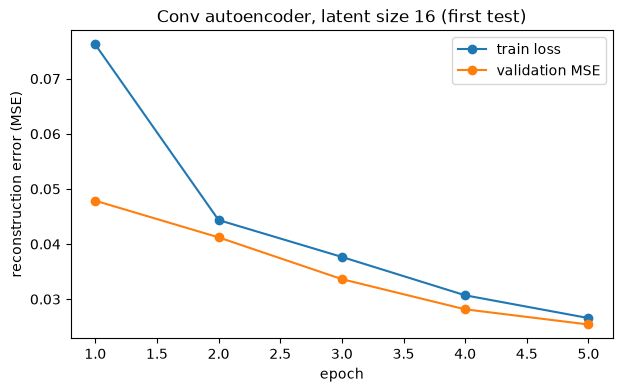

Figure saved to ..\figures\04_first_reconstructions.png


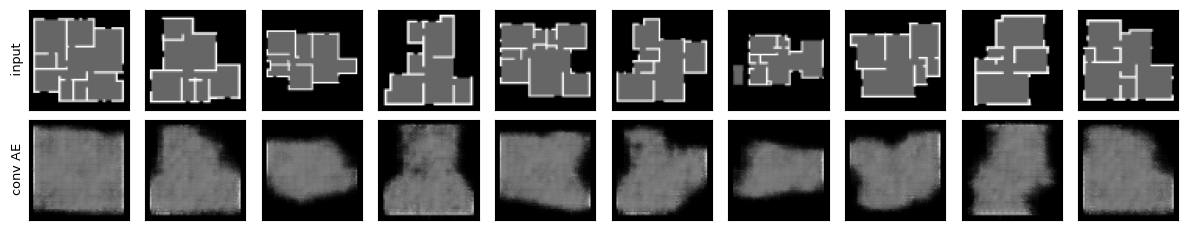

In [32]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(conv_hist["epoch"], conv_hist["train_loss"], marker="o", label="train loss")
ax.plot(conv_hist["epoch"], conv_hist["val_mse"], marker="o", label="validation MSE")
ax.set_xlabel("epoch"); ax.set_ylabel("reconstruction error (MSE)")
ax.set_title("Conv autoencoder, latent size 16 (first test)"); ax.legend()
save_fig("03_first_training_curve")
plt.show()

sample = X_val[:10]
show_images([sample, reconstruct(conv_ae, sample)], row_labels=["input", "conv AE"])
save_fig("04_first_reconstructions")
plt.show()

# 4. Compression: how small can the code be?

The **latent size** is the most important setting of an autoencoder. A **small** code compresses more but loses detail; a **large** code rebuilds better but learns less about the structure (and is useless for compression).

We train the convolutional AE with codes of **2, 8, 16 and 32** numbers and compare them **fairly**: the same training data, the same number of epochs, the same seed, scored on the same validation and test sets.

Our images are 64 × 64 = **4,096 pixels**, so a code of 16 numbers is a compression of 256×.

**Changes from the class notebook:**
- We train latent 16 again inside the loop. The model from section 3 trained only 5 epochs, so reusing it would not be fair.
- We added two columns that the Monday task asks for: **training time** and **validation MSE**.

In [33]:
results, models_by_latent, histories = [], {}, {}
for latent in [2, 8, 16, 32]:
    print(f"--- latent size {latent}")
    start = time.time()
    model, hist = train_autoencoder(ConvAE(latent_dim=latent), X_train, X_val, verbose=False)
    seconds = time.time() - start
    models_by_latent[latent], histories[latent] = model, hist
    results.append({"latent size": latent,
                    "compression": f"{IMG_SIZE * IMG_SIZE:,} → {latent} ({IMG_SIZE * IMG_SIZE / latent:.0f}×)",
                    "parameters": n_params(model),
                    "training time (s)": round(seconds),
                    "validation MSE": hist["val_mse"].iloc[-1],
                    "test MSE": reconstruction_error(model, X_test).mean().item()})
compression = pd.DataFrame(results).sort_values("latent size").reset_index(drop=True)
compression

--- latent size 2
trained in 36 s
--- latent size 8
trained in 32 s
--- latent size 16
trained in 27 s
--- latent size 32
trained in 29 s


,latent size,compression,parameters,training time (s),validation MSE,test MSE
0,2,"4,096 → 2 (2048×)",67011,36,0.0353,0.0354
1,8,"4,096 → 8 (512×)",116169,32,0.0267,0.0268
2,16,"4,096 → 16 (256×)",181713,27,0.0223,0.0224
3,32,"4,096 → 32 (128×)",312801,29,0.0214,0.0215


Figure saved to ..\figures\05_compression_reconstructions.png


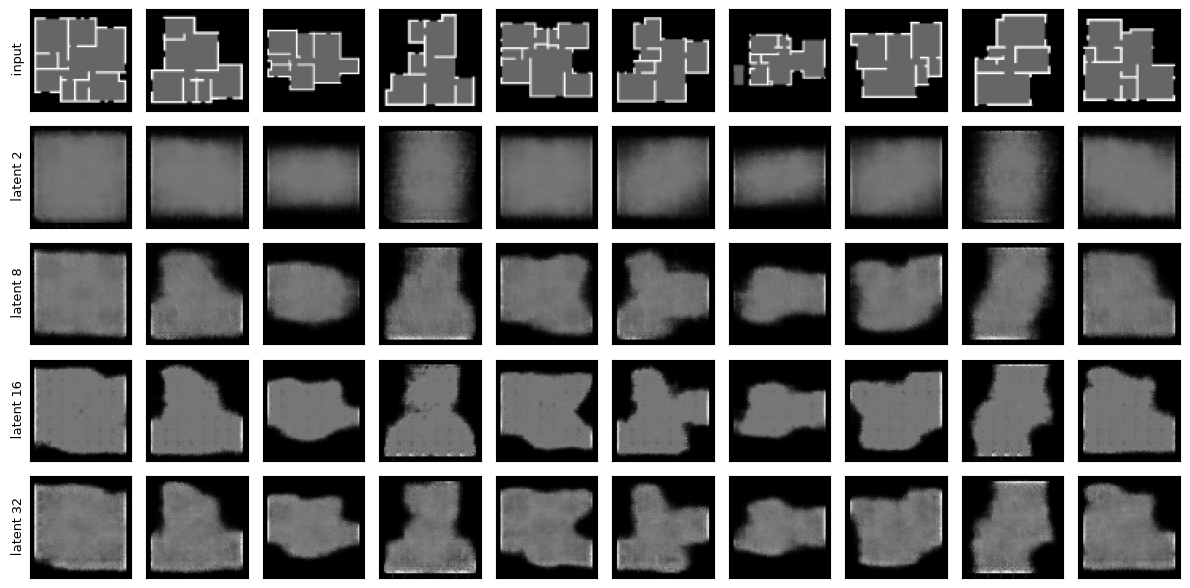

In [34]:
latents = sorted(models_by_latent)
sample = X_val[:10]
show_images([sample] + [reconstruct(models_by_latent[k], sample) for k in latents],
            row_labels=["input"] + [f"latent {k}" for k in latents])
save_fig("05_compression_reconstructions")
plt.show()

# 5. The latent space and similarity search

The encoder turns every plan into a short **code** (a few numbers). Plans with similar layouts should get similar codes, so they sit **close together** in the latent space.

**Our use case: similarity search.** An architect gives a floor plan, and the model finds the plans in the collection with the closest codes. It never saw any labels: it only learned to rebuild plans.

We use the model chosen in section 4 and the **test set**, which the model has never seen.

codes: (1632, 16)
Figure saved to ..\figures\07_latent_map.png


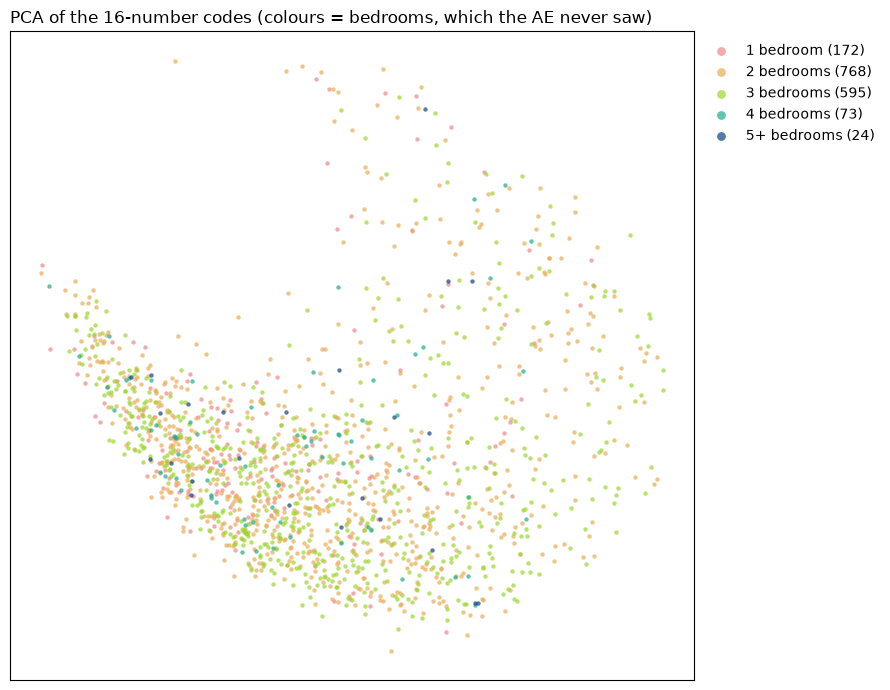

In [41]:
from sklearn.decomposition import PCA

CHOSEN_LATENT = 16                     # change to the latent size you chose in section 4
ae = models_by_latent[CHOSEN_LATENT]


@torch.no_grad()
def encode(model, X, batch_size=1000):
    # Copied from the class notebook: run only the encoder, keep the codes
    model.eval()
    return torch.cat([model.encoder(X[i:i + batch_size].to(DEVICE)) for i in range(0, len(X), batch_size)]).cpu()


codes_test = encode(ae, X_test)
print("codes:", tuple(codes_test.shape))

# Bedroom count of every test plan: NOT used by the model, only to colour the map
test_bedrooms = np.array([len(get_geometries(plans[i].get("bedroom"))) for i in test_idx]).clip(1, 5)

xy = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(codes_test.numpy())

BED_COLORS = {1: "#ef8686", 2: "#e7ad55", 3: "#9ad62a", 4: "#1cab8c", 5: "#104281"}   # light = few, dark = many
fig, ax = plt.subplots(figsize=(9, 7))
for b, color in BED_COLORS.items():
    part = test_bedrooms == b
    ax.scatter(xy[part, 0], xy[part, 1], s=10, alpha=0.7, color=color, linewidth=0,
               label=f"{b}{'+' if b == 5 else ''} bedroom{'s' if b > 1 else ''} ({part.sum()})")
ax.set_xticks([]); ax.set_yticks([])
ax.legend(markerscale=2, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title(f"PCA of the {CHOSEN_LATENT}-number codes (colours = bedrooms, which the AE never saw)", loc="left")
plt.tight_layout()
save_fig("07_latent_map")
plt.show()

query with 1 bedrooms -> matches have [2, 2, 2, 2, 2, 2] bedrooms (distance 24.27–40.02)
query with 2 bedrooms -> matches have [2, 2, 2, 2, 5, 3] bedrooms (distance 11.05–45.18)
query with 3 bedrooms -> matches have [3, 2, 3, 3, 3, 2] bedrooms (distance 21.74–36.74)
for comparison, the median distance between two random test plans is 89.13
Figure saved to ..\figures\08_similarity_search.png


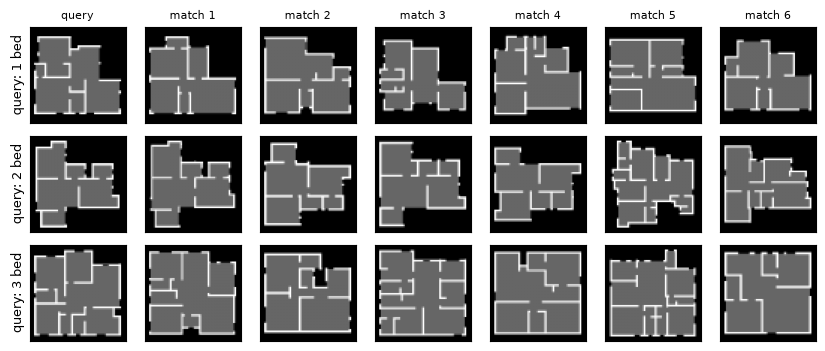

In [42]:
def most_similar(query_code, codes, k=6):
    # Copied from the class notebook: Euclidean distance between one code and all codes
    distances = torch.cdist(query_code.unsqueeze(0), codes).squeeze(0)
    best = distances.topk(k + 1, largest=False)      # +1: the query itself is in the collection (distance 0)
    return best.indices[1:], best.values[1:]


queries = [int(np.where(test_bedrooms == b)[0][0]) for b in [1, 2, 3]]   # the first test plan with 1, 2, 3 bedrooms
rows, labels = [], []
for q in queries:
    idx, dists = most_similar(codes_test[q], codes_test)
    rows.append(torch.cat([X_test[q:q + 1], X_test[idx]]))
    labels.append(f"query: {test_bedrooms[q]} bed")
    print(f"query with {test_bedrooms[q]} bedrooms -> matches have {test_bedrooms[idx.numpy()].tolist()} bedrooms "
          f"(distance {dists.min():.2f}–{dists.max():.2f})")
typical = torch.cdist(codes_test[:500], codes_test[:500]).median()
print(f"for comparison, the median distance between two random test plans is {typical:.2f}")

show_images(rows, row_labels=labels, titles=["query"] + [f"match {i}" for i in range(1, 7)])
save_fig("08_similarity_search")
plt.show()

Figure saved to ..\figures\09_similarity_plans.png


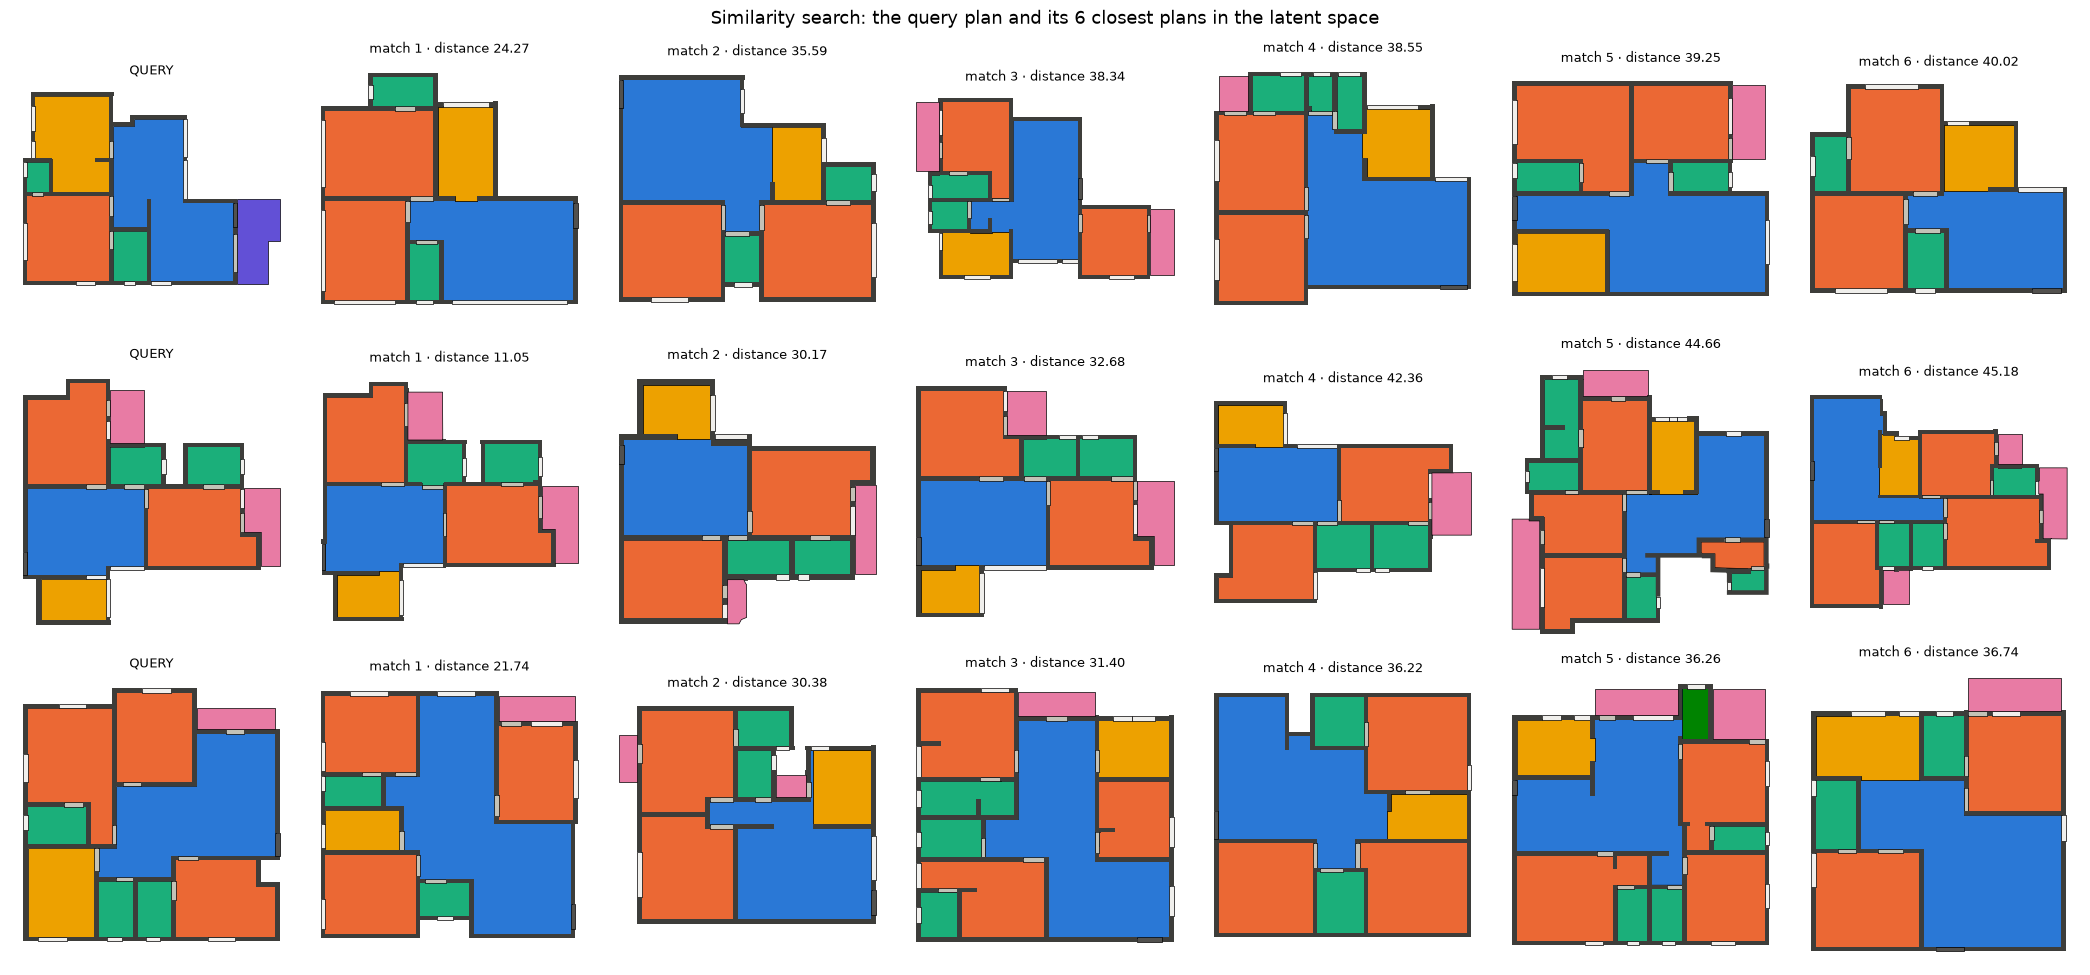

In [43]:
fig, axes = plt.subplots(len(queries), 7, figsize=(21, 3.3 * len(queries)))
for r, q in enumerate(queries):
    idx, dists = most_similar(codes_test[q], codes_test)
    for c, (i, d) in enumerate([(q, 0.0)] + list(zip(idx.tolist(), dists.tolist()))):
        plot_plan(plans[test_idx[i]], ax=axes[r, c], legend=False, tight=False)
        axes[r, c].set_title("QUERY" if c == 0 else f"match {c} · distance {d:.2f}", fontsize=9)
fig.suptitle("Similarity search: the query plan and its 6 closest plans in the latent space", fontsize=13)
plt.tight_layout()
save_fig("09_similarity_plans")
plt.show()

### What we see

- **The map:** do plans with the same number of bedrooms sit together, even though the AE never saw the bedroom count?
- **The matches:** do they have a similar **outline**? A similar **room layout**? Or only a similar size and shape?
- **The distances:** are the matches much closer than the median distance between two random plans?
- **Limits:** the model only sees the outline and the walls (no room types), so it can find plans with the same shape but different rooms.

c:\Users\Daria\anaconda3\envs\hackathon\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Daria\anaconda3\envs\hackathon\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Daria\anaconda3\envs\hackathon\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting ran

Figure saved to ..\figures\07b_latent_umap.png


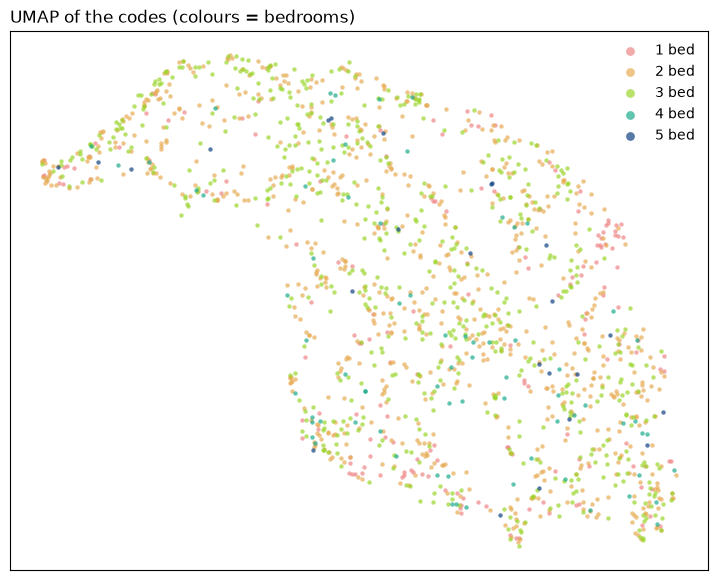

In [45]:
import umap

xy_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(codes_test.numpy())
fig, ax = plt.subplots(figsize=(9, 7))
for b, color in BED_COLORS.items():
    part = test_bedrooms == b
    ax.scatter(xy_umap[part, 0], xy_umap[part, 1], s=10, alpha=0.7, color=color, linewidth=0, label=f"{b} bed")
ax.set_xticks([]); ax.set_yticks([])
ax.legend(markerscale=2, frameon=False)
ax.set_title("UMAP of the codes (colours = bedrooms)", loc="left")
save_fig("07b_latent_umap")
plt.show()

**Conclusion:** The bedrooms are mixed on the map because our images show only the outline and the walls, not the room types. The model learned the **shape** of the plan, not its rooms. To make it see bedrooms, we would need to draw the room types into the input image.

Check 1: colour the map by something the model CAN see (shape). If the codes are organised by shape, you’ll see smooth colour changes here, unlike the bedroom colours.

Figure saved to ..\figures\07c_latent_umap_shape.png


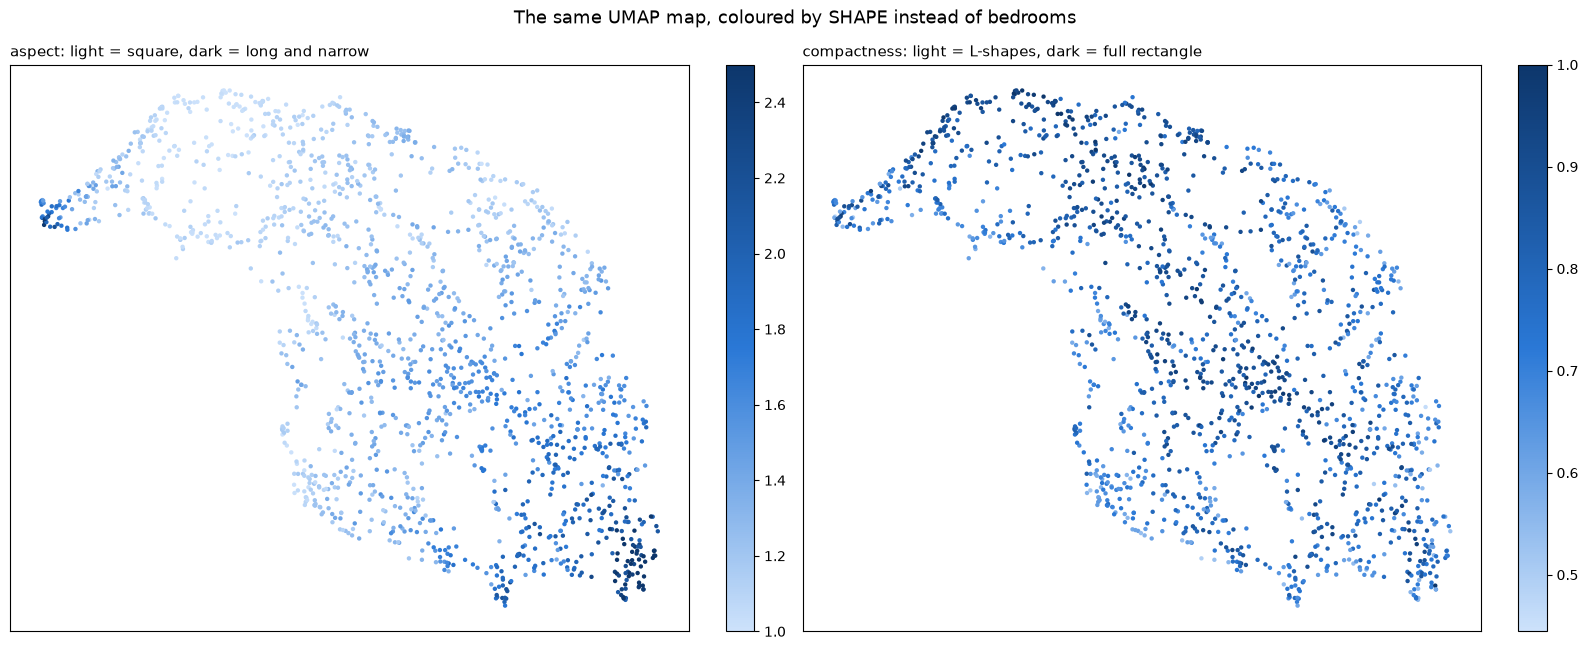

In [46]:
def shape_stats(plan):
    # aspect: 1 = square, 2 = twice as long as wide; compactness: 1 = a full rectangle
    inner = plan["inner"]
    x1, y1, x2, y2 = inner.bounds
    w, h = x2 - x1, y2 - y1
    return max(w, h) / min(w, h), inner.area / (w * h)


stats = np.array([shape_stats(plans[i]) for i in test_idx])
test_aspect, test_compact = stats[:, 0], stats[:, 1]

blue_ramp = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#2a78d6", "#0d366b"])   # light = low, dark = high
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, values, title in [(axes[0], test_aspect.clip(1, 2.5), "aspect: light = square, dark = long and narrow"),
                          (axes[1], test_compact, "compactness: light = L-shapes, dark = full rectangle")]:
    sc = ax.scatter(xy_umap[:, 0], xy_umap[:, 1], c=values, cmap=blue_ramp, s=10, linewidth=0)
    fig.colorbar(sc, ax=ax, fraction=0.04)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, loc="left", fontsize=11)
fig.suptitle("The same UMAP map, coloured by SHAPE instead of bedrooms", fontsize=13)
plt.tight_layout()
save_fig("07c_latent_umap_shape")
plt.show()

**Conclusion:** The latent space is organised mainly by the **proportions** of the plan: square plans on one side, long and narrow plans on the other. The outline shape (L-shape vs rectangle) has a weaker effect, and the bedroom count has almost none. Long plans form two separate groups, probably horizontal vs vertical, because our images are not rotated to a common direction. So our similarity search finds plans with a **similar outline**, not a similar room layout.

Check 2: a number instead of the eye. For every test plan, look at its 6 closest plans in the latent space. How often do they have the same property? Then compare with random chance. This is better than judging a picture.

In [47]:
from sklearn.neighbors import NearestNeighbors


def neighbour_agreement(codes, labels, k=6):
    # Share of the k nearest neighbours (in the latent space) that have the same label as the plan
    _, idx = NearestNeighbors(n_neighbors=k + 1).fit(codes).kneighbors(codes)
    return (labels[idx[:, 1:]] == labels[:, None]).mean()


codes_np = codes_test.numpy()
checks = {
    "bedrooms (1, 2, 3, 4, 5+)": test_bedrooms,
    "shape: square / medium / long": pd.cut(test_aspect, [0, 1.25, 1.6, 99], labels=False),
    "outline: L-shape / medium / rectangle": pd.cut(test_compact, [0, 0.75, 0.9, 1.01], labels=False),
}
rows = []
for name, labels in checks.items():
    labels = np.asarray(labels)
    random_chance = (pd.Series(labels).value_counts(normalize=True) ** 2).sum()   # chance that 2 random plans match
    rows.append({"property": name, "neighbours that match": neighbour_agreement(codes_np, labels),
                 "random chance": random_chance})
agreement = pd.DataFrame(rows).set_index("property")
agreement["better than random"] = agreement["neighbours that match"] / agreement["random chance"]
agreement.round(2)

,neighbours that match,random chance,better than random
property,,,
"bedrooms (1, 2, 3, 4, 5+)",0.4300,0.3700,1.1600
shape: square / medium / long,0.7800,0.3400,2.2900
outline: L-shape / medium / rectangle,0.6000,0.3700,1.6500


# 6. Denoising

A **denoising autoencoder** gets a plan with random noise added, and learns to rebuild the **clean** plan. It must learn what a floor plan looks like, so it can tell the plan from the noise.

**Why it matters for architects:** old scanned drawings, photos of printed plans or low-quality images often come with noise. A denoising AE can clean them before we use them.

We compare two models on the same noisy plans:
- the **normal AE** from section 4 (latent 32, never saw noise during training);
- a **denoising AE** (latent 32, trained with noise `0.35`).

trained in 25 s
Figure saved to ..\figures\10_denoising.png


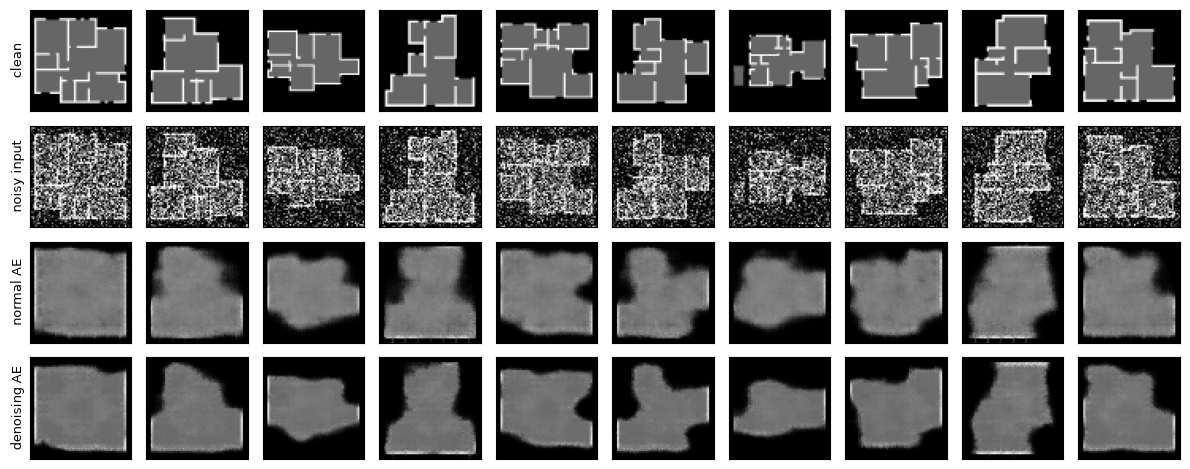

,MSE vs clean,lower than noisy
row,,
noisy input,0.0750,0%
normal AE,0.0334,55%
denoising AE,0.0242,68%


In [48]:
NOISE = 0.35
denoise_ae, denoise_hist = train_autoencoder(ConvAE(latent_dim=32), X_train, X_val, noise=NOISE, verbose=False)

sample = X_val[:10]
torch.manual_seed(RANDOM_STATE)
noisy_sample = (sample + NOISE * torch.randn_like(sample)).clamp(0, 1)

plain = reconstruct(models_by_latent[32], noisy_sample)     # normal AE from section 4, never trained on noise
cleaned = reconstruct(denoise_ae, noisy_sample)             # trained with noise

show_images([sample, noisy_sample, plain, cleaned],
            row_labels=["clean", "noisy input", "normal AE", "denoising AE"])
save_fig("10_denoising")
plt.show()

# How far is each row from the clean plans? (lower = better)
noisy_mse = ((noisy_sample - sample) ** 2).mean().item()
rows = []
for name, out in [("noisy input", noisy_sample), ("normal AE", plain), ("denoising AE", cleaned)]:
    mse = ((out - sample) ** 2).mean().item()
    rows.append({"row": name, "MSE vs clean": mse, "lower than noisy": f"{100 * (1 - mse / noisy_mse):.0f}%"})
pd.DataFrame(rows).set_index("row").round(4)

**Conclusion:** Both models remove most of the noise. The normal AE lowers the error by 55%, the denoising AE by 68%: training with noise helps, and the outlines of the denoising AE are sharper and closer to the real shape. But neither model rebuilds the inner walls, even though they are still visible in the noisy input. The limit is the code size (32 numbers), not the noise. These numbers are measured on 10 validation plans only.

fun for architects. 
# 6.2: 
 We erase a square in the middle of each plan and see what the models “imagine” there. Neither model was trained for this, so it’s a real test.

Figure saved to ..\figures\11_fill_the_hole.png


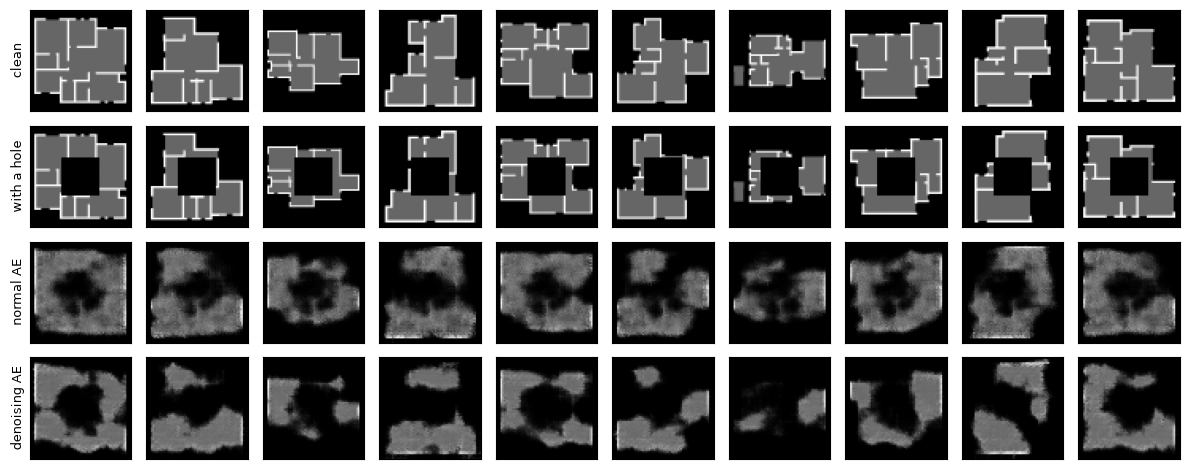

In [49]:
holed = sample.clone()
holed[:, :, 20:44, 20:44] = 0          # erase a 24 × 24 pixel square in the middle

show_images([sample, holed, reconstruct(models_by_latent[32], holed), reconstruct(denoise_ae, holed)],
            row_labels=["clean", "with a hole", "normal AE", "denoising AE"])
save_fig("11_fill_the_hole")
plt.show()

**Conclusion:** Neither model can fill a missing part of a plan. In our images, black means "outside the apartment", so both models read the hole as a courtyard and keep it. The denoising AE does even worse than the normal AE here: it was trained to remove small noise, not to fill large missing areas, and some plans break into pieces. To fill holes, the model would need to be trained with holes (inpainting), and "missing" would need a different value than "outside".

# 7. Anomaly detection

The recipe from class:
1. Train the autoencoder on **normal** data only.
2. A normal plan is rebuilt well. An **anomaly** is rebuilt badly: its **reconstruction error is high**.
3. Choose a **threshold** on the error using **validation** data: above the threshold = anomaly.
4. Measure it **once** on the test set.

**Our "normal" data:** real floor plans. ResPlan has no labels for "bad" plans, so we **create the anomalies** from test plans that the model never saw. They copy real data errors:

| Anomaly | What we do | Real-world example |
|---|---|---|
| **shuffled** | cut the plan in 4 quarters and put them back in the wrong places | a drawing put together wrong |
| **stray lines** | draw 4 random white lines | scan noise, a bad vectorisation |
| **hole** | erase a square in the middle | a missing part of the drawing |

**App idea:** check if an uploaded floor plan is a valid, complete drawing before using it.

7.1: the model and the threshold. Every training plan is “normal”, so the model from section 4 is already trained on normal data only, and we can reuse it. The threshold is chosen on validation data, like the lecturer’s: 95% of normal plans stay below it.

In [50]:
anomaly_ae = models_by_latent[16]     # section 4: trained on the training plans, which are all normal

# The threshold: the error that 95% of the normal validation plans stay below
val_errors = reconstruction_error(anomaly_ae, X_val)
THRESHOLD = float(np.quantile(val_errors.numpy(), 0.95))
print(f"threshold = {THRESHOLD:.4f} (95% of the normal validation plans are below it)")

threshold = 0.0331 (95% of the normal validation plans are below it)


Figure saved to ..\figures\12_anomaly_examples.png


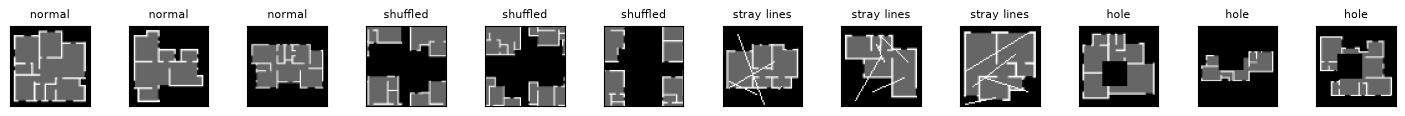

In [51]:
rng_anom = np.random.default_rng(RANDOM_STATE)


def shuffle_quarters(x):
    # Cut every plan into 4 quarters and put them back in the wrong places
    h = IMG_SIZE // 2
    tl, tr, bl, br = x[..., :h, :h], x[..., :h, h:], x[..., h:, :h], x[..., h:, h:]
    return torch.cat([torch.cat([br, bl], dim=-1), torch.cat([tr, tl], dim=-1)], dim=-2)


def add_stray_lines(x, n_lines=4):
    # Draw a few random white lines on every plan
    out = x.clone().numpy()
    for img in out:
        for _ in range(n_lines):
            (x1, y1), (x2, y2) = rng_anom.integers(0, IMG_SIZE, size=(2, 2))
            cv2.line(img[0], (int(x1), int(y1)), (int(x2), int(y2)), 1.0, 1)
    return torch.from_numpy(out)


def cut_hole(x, size=20):
    # Erase a square near the middle of every plan
    out = x.clone()
    for k in range(len(out)):
        r, c = (IMG_SIZE - size) // 2 + rng_anom.integers(-8, 9, size=2)
        out[k, :, int(r):int(r) + size, int(c):int(c) + size] = 0
    return out


parts = [torch.from_numpy(p) for p in np.array_split(np.arange(len(X_test)), 4)]
X_eval = torch.cat([X_test[parts[0]],
                    shuffle_quarters(X_test[parts[1]]),
                    add_stray_lines(X_test[parts[2]]),
                    cut_hole(X_test[parts[3]])])
eval_type = np.repeat(["normal", "shuffled", "stray lines", "hole"], [len(p) for p in parts])
y_eval = torch.tensor(eval_type != "normal").int()          # 1 = anomaly, 0 = normal

picks = np.concatenate([np.where(eval_type == t)[0][:3] for t in ["normal", "shuffled", "stray lines", "hole"]])
show_images([X_eval[picks]], titles=[eval_type[i] for i in picks])
save_fig("12_anomaly_examples")
plt.show()

In [52]:
test_errors = reconstruction_error(anomaly_ae, X_eval)
predicted = (test_errors > THRESHOLD).int()

print(f"test plans: {len(X_eval):,} ({int(y_eval.sum()):,} anomalies)")
print(f"ROC AUC   {roc_auc_score(y_eval, test_errors):.3f}  (1.0 = errors separate the two groups perfectly)")
print(f"precision {precision_score(y_eval, predicted):.3f}  (of the flagged plans, share that really are anomalies)")
print(f"recall    {recall_score(y_eval, predicted):.3f}  (share of the anomalies that were flagged)")

# Which kind of damage does the model find?
errs = test_errors.numpy()
normal_err = errs[eval_type == "normal"]
rows = []
for t in ["shuffled", "stray lines", "hole"]:
    e = errs[eval_type == t]
    y = np.r_[np.zeros(len(normal_err)), np.ones(len(e))]
    rows.append({"anomaly type": t, "plans": len(e),
                 "ROC AUC": roc_auc_score(y, np.r_[normal_err, e]),
                 "flagged (recall)": (e > THRESHOLD).mean()})
pd.DataFrame(rows).set_index("anomaly type").round(3)

test plans: 1,632 (1,224 anomalies)
ROC AUC   0.951  (1.0 = errors separate the two groups perfectly)
precision 0.972  (of the flagged plans, share that really are anomalies)
recall    0.820  (share of the anomalies that were flagged)


,plans,ROC AUC,flagged (recall)
anomaly type,,,
shuffled,408,1.0000,1.0000
stray lines,408,0.9330,0.7080
hole,408,0.9190,0.7520


**Conclusion:** The reconstruction error separates normal plans from broken drawings very well (ROC AUC 0.95). Shuffled plans are found perfectly (AUC 1.0, all flagged): the model has never seen rooms in the wrong places. Stray lines and holes are harder (AUC 0.93 and 0.92, about 70–75% flagged): a thin line or a small hole changes only a few pixels, so the average error stays low. Limits: the anomalies are made by us, and 3 of 4 test plans are anomalies, much more than in real life, so the precision (0.97) is too optimistic.

Figure saved to ..\figures\13_anomaly_histogram.png


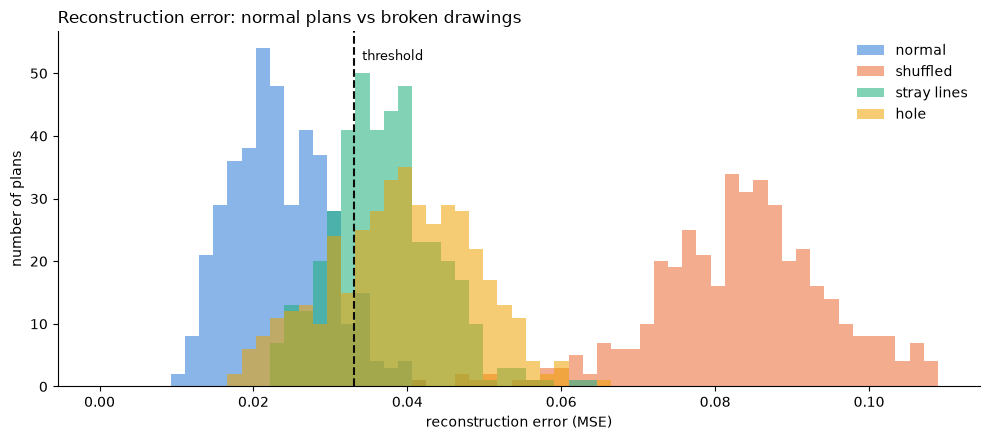

In [53]:
TYPE_COLORS = {"normal": "#2a78d6", "shuffled": "#eb6834", "stray lines": "#1baf7a", "hole": "#eda100"}
bins = np.linspace(0, np.quantile(errs, 0.995), 60)

fig, ax = plt.subplots(figsize=(10, 4.5))
for t, color in TYPE_COLORS.items():
    ax.hist(errs[eval_type == t], bins=bins, alpha=0.55, color=color, label=t)
ax.axvline(THRESHOLD, color="#0b0b0b", linestyle="--", linewidth=1.5)
ax.text(THRESHOLD, ax.get_ylim()[1] * 0.95, "  threshold", va="top", fontsize=9)
ax.set_xlabel("reconstruction error (MSE)"); ax.set_ylabel("number of plans")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title("Reconstruction error: normal plans vs broken drawings", loc="left")
plt.tight_layout()
save_fig("13_anomaly_histogram")
plt.show()

**What the histogram shows:** Normal plans have low errors (mostly 0.01–0.035). Shuffled plans are far to the right (0.06–0.11), with no overlap at all: a big change gives a big error. Stray lines and holes sit just around the threshold, and part of them overlaps with the normal plans: a small change gives only a small error. Some holes even get a lower error than normal plans, probably because the model rebuilds them as a courtyard. The threshold is a trade-off: moving it left finds more damaged plans, but also flags more good plans by mistake.

Figure saved to ..\figures\14_anomaly_error_maps.png


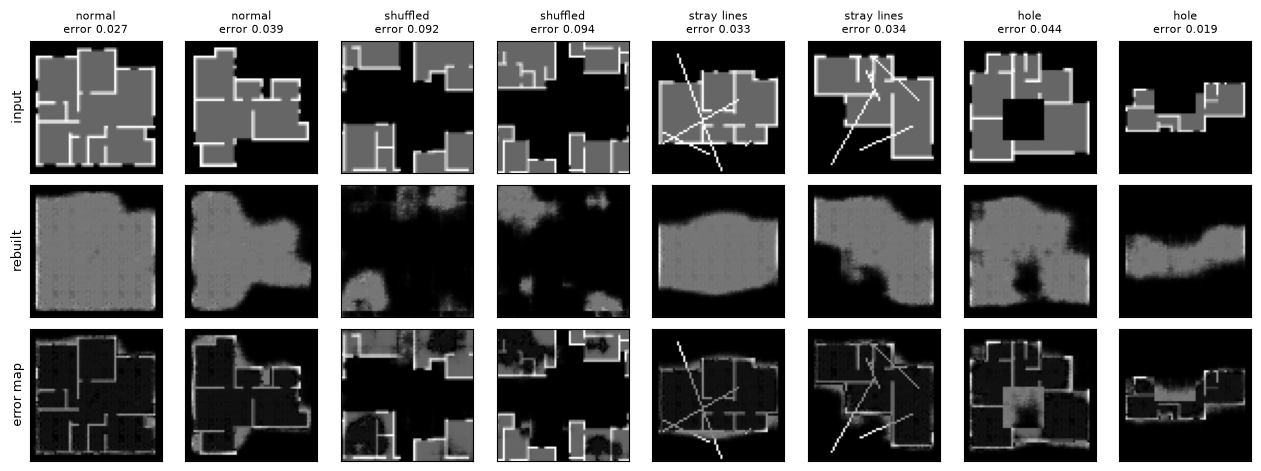

In [54]:
picks = np.concatenate([np.where(eval_type == t)[0][:2] for t in TYPE_COLORS])
inputs = X_eval[picks]
rebuilt = reconstruct(anomaly_ae, inputs)
show_images([inputs, rebuilt, (inputs - rebuilt).abs()],
            titles=[f"{eval_type[i]}\nerror {errs[i]:.3f}" for i in picks],
            row_labels=["input", "rebuilt", "error map"], size=1.6)
save_fig("14_anomaly_error_maps")
plt.show()

# 8. Generative design with a VAE

A normal autoencoder's latent space has **gaps**: decode a random code and you often get noise. A **variational autoencoder** (VAE) fixes this. Its encoder outputs, for each plan, a small **cloud** of codes (a mean and a spread) instead of one point, and the loss gets a second term that keeps all clouds close to a standard normal distribution:

    loss = reconstruction error  +  β · KL divergence

The result is a **smooth** latent space: a random code decodes to a plausible plan, and walking from one code to another **blends** two designs.

**Our test:** generate new plans from random codes, and blend from a **square** plan to a **long, narrow** plan (in section 5 we saw that proportions are what our codes hold best).

In [55]:
class ConvVAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.latent_dim = latent_dim
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),    # 64 -> 32
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),   # 32 -> 16
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),   # 16 -> 8
            nn.Flatten(),
        )
        self.to_mean = nn.Linear(64 * 8 * 8, latent_dim)
        self.to_logvar = nn.Linear(64 * 8 * 8, latent_dim)
        self.decoder = ConvAE(latent_dim).decoder          # the same decoder as our ConvAE

    def encoder(self, x):
        return self.to_mean(self.features(x))               # the mean code: used for similarity search

    def forward(self, x):
        h = self.features(x)
        mean, logvar = self.to_mean(h), self.to_logvar(h)
        z = mean + torch.randn_like(mean) * torch.exp(0.5 * logvar)   # sample a code from the cloud
        self.kl = -0.5 * torch.mean(torch.sum(1 + logvar - mean ** 2 - logvar.exp(), dim=1))
        return self.decoder(z)


BETA = 1.0
def vae_loss(output, target, model):
    reconstruction = nn.functional.binary_cross_entropy(output, target, reduction="sum") / len(target)
    return reconstruction + BETA * model.kl


vae, vae_hist = train_autoencoder(ConvVAE(latent_dim=16), X_train, X_val, epochs=10, loss_fn=vae_loss, verbose=False)

trained in 28 s


from aspect 1.00 (square) to aspect 2.20 (long)
Figure saved to ..\figures\15_vae_generation.png


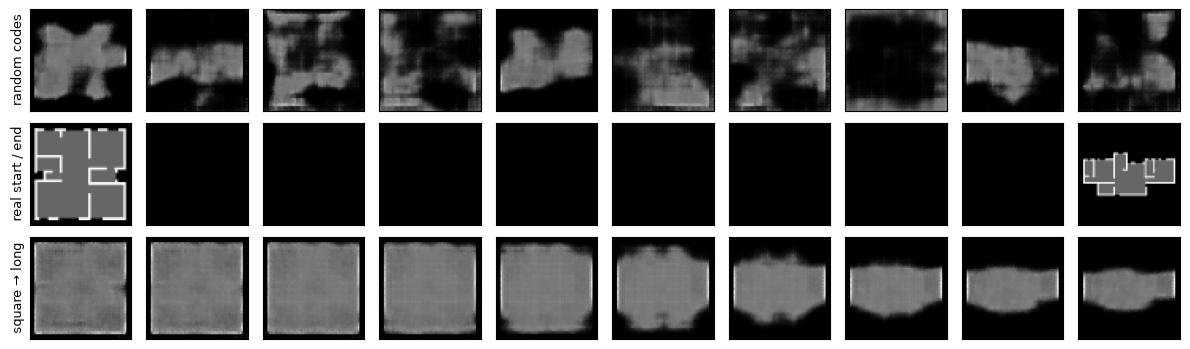

In [56]:
# 1) Brand-new plans: decode random codes drawn from a standard normal
torch.manual_seed(RANDOM_STATE)
with torch.no_grad():
    vae.eval()
    random_codes = torch.randn(10, vae.latent_dim, device=DEVICE)
    generated = vae.decoder(random_codes).cpu()

# 2) Blending: from the most square test plan to a long, narrow one
def aspect_of(plan):
    x1, y1, x2, y2 = plan["inner"].bounds
    return max(x2 - x1, y2 - y1) / min(x2 - x1, y2 - y1)


aspects = np.array([aspect_of(plans[i]) for i in test_idx])
i_square = int(np.argmin(np.abs(aspects - 1.0)))        # closest to a square
i_long = int(np.argmin(np.abs(aspects - 2.2)))          # about 2.2 times longer than wide
print(f"from aspect {aspects[i_square]:.2f} (square) to aspect {aspects[i_long]:.2f} (long)")

code_a = encode(vae, X_test[i_square:i_square + 1])
code_b = encode(vae, X_test[i_long:i_long + 1])
steps = torch.linspace(0, 1, 10).unsqueeze(1)
with torch.no_grad():
    blend = vae.decoder(((1 - steps) * code_a + steps * code_b).to(DEVICE)).cpu()

ends = torch.cat([X_test[i_square:i_square + 1]] + [torch.zeros_like(X_test[:1])] * 8 + [X_test[i_long:i_long + 1]])
show_images([generated, ends, blend], row_labels=["random codes", "real start / end", "square → long"])
save_fig("15_vae_generation")
plt.show()

### What we conclude

- **Random codes:** about half of them (1, 2, 5, 9) decode to plausible building outlines; the others are patchy or almost empty. The latent space is smoother than a normal AE's, but not smooth everywhere yet.
- **The blend:** the walk from the most square plan (aspect 1.0) to a long, narrow plan (aspect 2.2) changes **gradually**: the square gets lower and wider step by step, and every intermediate step is a plausible outline. This is generative design in miniature: the steps in between are new shapes that are not in the dataset.
- **Limits:** the generated plans have **no inner walls**: even the real start plan (a square with cross-shaped walls) is decoded as a full square. The VAE learned outlines and proportions, not room layouts.
- **Possible improvement:** our images have 4,096 pixels, so the reconstruction term may outweigh the KL term. A larger `BETA` or more epochs could make random codes more plausible, at the cost of blurrier reconstructions.

# 9. Saving the model for the model server

On Tuesday the model moves to a **model server**. We save everything it needs:

| File | Contents | Why |
|---|---|---|
| `anomaly_ae.onnx` | The model in **ONNX** format: architecture **and** weights in one file | The server runs it with ONNX Runtime, without PyTorch |
| `anomaly_ae.pt` | The PyTorch weights | To train further in PyTorch later |
| `anomaly_ae_config.json` | Image size, preprocessing, threshold, anomaly types | To prepare inputs exactly as in training and to read the output |
| `examples/*.png` | One normal plan and one of each anomaly type | Example inputs for the server's page |

We export the **anomaly detection** model from section 7 (ConvAE, latent 16). The files go into `model_app/` (for the server) and `models/` (for Hugging Face). `.onnx` and `.pt` files are **not** committed to GitHub: they live on Hugging Face.

⚠️ The server must use the **same preprocessing** as training: greyscale, 64 × 64, pixels 0–1, floor grey (0.4), walls white (1.0), black background.

In [57]:
import shutil

MODEL_APP_DIR = Path("../model_app")             # for the model server (Tuesday)
(MODEL_APP_DIR / "examples").mkdir(parents=True, exist_ok=True)

anomaly_ae = anomaly_ae.cpu().eval()
torch.save(anomaly_ae.state_dict(), MODEL_APP_DIR / "anomaly_ae.pt")

# Export to ONNX. dynamic_shapes: the first dimension (the number of images) may change
example_input = X_test[:1]
torch.onnx.export(anomaly_ae, (example_input,), MODEL_APP_DIR / "anomaly_ae.onnx",
                  input_names=["image"], output_names=["reconstruction"],
                  dynamic_shapes={"x": {0: torch.export.Dim("batch")}}, external_data=False, verbose=False)

config = {
    "architecture": "ConvAE",
    "latent_dim": 16,
    "image_size": IMG_SIZE,
    "preprocessing": (f"each plan scaled to fit {IMG_SIZE}x{IMG_SIZE} (5% margin, aspect ratio kept), "
                      "greyscale, pixels 0-1: background black (0), floor grey (0.4), walls white (1.0)"),
    "threshold": THRESHOLD,
    "threshold_rule": "95th percentile of the reconstruction error on normal validation plans",
    "normal_classes": ["real ResPlan floor plans"],
    "anomaly_classes_in_test": ["shuffled", "stray lines", "hole"],
    "test_roc_auc": round(float(roc_auc_score(y_eval, test_errors)), 3),
}
(MODEL_APP_DIR / "anomaly_ae_config.json").write_text(json.dumps(config, indent=2))

# One example image of each type (normal + the three anomalies)
for t in ["normal", "shuffled", "stray lines", "hole"]:
    i = int(np.where(eval_type == t)[0][0])
    plt.imsave(MODEL_APP_DIR / "examples" / f"{t.replace(' ', '_')}.png",
               X_eval[i].squeeze().numpy(), cmap="gray", vmin=0, vmax=1)

# The same model files go to models/ for Hugging Face
for name in ["anomaly_ae.onnx", "anomaly_ae_config.json"]:
    shutil.copy(MODEL_APP_DIR / name, MODEL_DIR / name)

for path in sorted(MODEL_APP_DIR.glob("*.*")) + sorted((MODEL_APP_DIR / "examples").glob("*")):
    print(f"{str(path):45s} {path.stat().st_size / 1024:8.1f} KB")

W1117 00:11:34.079000 31260 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::nms
W1117 00:11:34.081000 31260 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align
W1117 00:11:34.083000 31260 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool
W1117 00:11:34.084000 31260 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::deform_conv2d


..\model_app\.gitkeep                              0.0 KB
..\model_app\anomaly_ae.onnx                     735.0 KB
..\model_app\anomaly_ae.pt                       715.9 KB
..\model_app\anomaly_ae_config.json                0.5 KB
..\model_app\examples\hole.png                     0.8 KB
..\model_app\examples\normal.png                   1.0 KB
..\model_app\examples\shuffled.png                 1.0 KB
..\model_app\examples\stray_lines.png              1.0 KB


In [58]:
# Check: the ONNX file, run by ONNX Runtime, gives the same scores as PyTorch
import onnxruntime as ort

session = ort.InferenceSession(MODEL_APP_DIR / "anomaly_ae.onnx")
batch = X_eval[:5].numpy()
onnx_output = session.run(None, {"image": batch})[0]
onnx_scores = ((onnx_output - batch) ** 2).mean(axis=(1, 2, 3))
torch_scores = reconstruction_error(anomaly_ae.to(DEVICE), X_eval[:5]).numpy()
print("PyTorch:     ", torch_scores.round(5))
print("ONNX Runtime:", onnx_scores.round(5))
print("same scores:", np.allclose(torch_scores, onnx_scores, atol=1e-6))

PyTorch:      [0.02687 0.03898 0.01518 0.03553 0.02448]
ONNX Runtime: [0.02687 0.03898 0.01518 0.03553 0.02448]
same scores: True


# 10. Version 2: a model that learns rooms, walls, doors and windows

Version 1 learned only the **outline**. In version 2 every element gets its own **layer (channel)**, so the model can tell them apart:

| Layers | Why |
|---|---|
| wall, door, window | thin elements: drawn a bit thicker, and their error counts more (walls 3×, doors and windows 8×) |
| living, bedroom, bathroom, kitchen | the room layout |

Doors and windows are only about 2% of the pixels each, so we use **128 × 128** images (at 64 px a door is 2–3 pixels). Every plan is **turned so the long side is horizontal**. The training images are stored as whole numbers 0–255 to use 4× less memory; the model converts them itself.

10.1

In [59]:
CHANNELS = ["wall", "door", "window", "living", "bedroom", "bathroom", "kitchen"]
THIN_LAYERS = ["wall", "door", "window"]   # thin elements: drawn thicker so they survive shrinking
IMG_SIZE_R = 128
DRAW_SIZE_R = 512
THICKEN = 4                                 # pixels added around thin elements (at 512 px)


def rotate_90(geoms):
    return [affinity.rotate(g, 90, origin=(0, 0)) for g in geoms]


def bounds_of(geoms):
    b = np.array([g.bounds for g in geoms])
    return b[:, 0].min(), b[:, 1].min(), b[:, 2].max(), b[:, 3].max()


def plan_to_rooms(plan, size=IMG_SIZE_R, draw_size=DRAW_SIZE_R, margin=MARGIN):
    layers = {c: get_geometries(plan.get(c)) for c in CHANNELS}
    layers["door"] = layers["door"] + get_geometries(plan.get("front_door"))   # the entrance is a door too
    outline = get_geometries(plan.get("inner")) + layers["wall"]
    if not outline:
        return np.zeros((len(CHANNELS), size, size), dtype=np.float32)

    minx, miny, maxx, maxy = bounds_of(outline)
    if (maxy - miny) > (maxx - minx):              # a "standing" plan: turn it so the long side is horizontal
        layers = {c: rotate_90(g) for c, g in layers.items()}
        outline = rotate_90(outline)
        minx, miny, maxx, maxy = bounds_of(outline)

    w, h = maxx - minx, maxy - miny
    scale = draw_size * (1 - 2 * margin) / max(w, h)
    xoff = (draw_size - w * scale) / 2 - minx * scale
    yoff = (draw_size + h * scale) / 2 + miny * scale

    out = np.zeros((len(CHANNELS), size, size), dtype=np.float32)
    for k, c in enumerate(CHANNELS):
        geoms = [affinity.affine_transform(g, [scale, 0, 0, -scale, xoff, yoff]) for g in layers[c]]
        mask = geometry_to_mask(geoms, shape=(draw_size, draw_size))
        if c in THIN_LAYERS:
            mask = cv2.dilate(mask, np.ones((3, 3), np.uint8), iterations=THICKEN)
        out[k] = cv2.resize(mask.astype(np.float32) / 255.0, (size, size), interpolation=cv2.INTER_AREA)
    return out


CACHE_ROOMS = DATA_DIR / f"resplan_7layers_{IMG_SIZE_R}px.npz"


def build_rooms(indices):
    # every plan is turned into whole numbers 0-255 right away, so the big float version never exists
    return np.stack([(plan_to_rooms(plans[i]) * 255).round().astype(np.uint8) for i in indices])


if CACHE_ROOMS.exists():
    cached = np.load(CACHE_ROOMS)
    R_train_u8, R_val_u8, R_test_u8 = cached["train"], cached["val"], cached["test"]
    print(f"loaded from {CACHE_ROOMS}")
else:
    start = time.time()
    R_train_u8, R_val_u8, R_test_u8 = build_rooms(train_idx), build_rooms(val_idx), build_rooms(test_idx)
    np.savez_compressed(CACHE_ROOMS, train=R_train_u8, val=R_val_u8, test=R_test_u8)
    print(f"drew the plans in {time.time() - start:.0f} s, saved to {CACHE_ROOMS}")

R_train = torch.from_numpy(R_train_u8)             # stays 0-255 (small); the model converts it
R_val = torch.from_numpy(R_val_u8).float() / 255   # 0-1, for the validation error and the figures
R_test = torch.from_numpy(R_test_u8).float() / 255
print("train", tuple(R_train.shape), R_train.dtype, "| validation", tuple(R_val.shape), "| test", tuple(R_test.shape))

drew the plans in 216 s, saved to ..\..\data\resplan_7layers_128px.npz
train (13053, 7, 128, 128) torch.uint8 | validation (1632, 7, 128, 128) | test (1632, 7, 128, 128)


10.2

Figure saved to ..\figures\16_layers_input.png


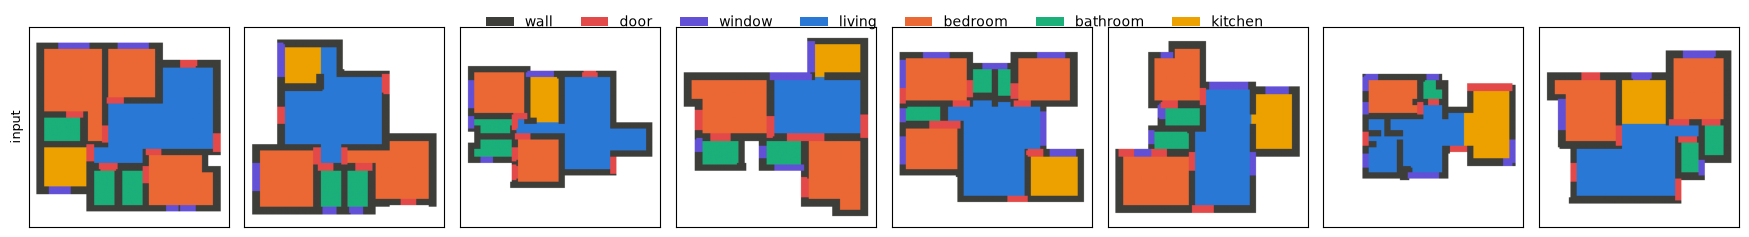

In [60]:
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

LAYER_COLORS = {"wall": "#3d3d3a", "door": "#e34948", "window": "#6250d6",
                "living": "#2a78d6", "bedroom": "#eb6834", "bathroom": "#1baf7a", "kitchen": "#eda100"}


def to_color(x, thin_threshold=0.3, room_threshold=0.5):
    # x: (7, H, W) -> RGB picture: rooms by their strongest layer, then walls, windows and doors on top
    x = x.detach().cpu().float().numpy() if torch.is_tensor(x) else x
    rgb = np.ones((x.shape[1], x.shape[2], 3))
    rooms = CHANNELS[3:]
    room_idx, room_val = x[3:].argmax(0), x[3:].max(0)
    for k, name in enumerate(rooms):
        rgb[(room_idx == k) & (room_val > room_threshold)] = to_rgb(LAYER_COLORS[name])
    for name in ["wall", "window", "door"]:
        rgb[x[CHANNELS.index(name)] > thin_threshold] = to_rgb(LAYER_COLORS[name])
    return rgb


def show_rooms(rows, row_labels, n=8):
    fig, axes = plt.subplots(len(rows), n, figsize=(2.2 * n, 2.3 * len(rows)), squeeze=False)
    for r, batch in enumerate(rows):
        for c in range(n):
            axes[r, c].imshow(to_color(batch[c]))
            axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        axes[r, 0].set_ylabel(row_labels[r], fontsize=9)
    fig.legend(handles=[Patch(facecolor=LAYER_COLORS[c], label=c) for c in CHANNELS],
               loc="upper center", ncol=len(CHANNELS), frameon=False, bbox_to_anchor=(0.5, 1.04))
    plt.tight_layout()


show_rooms([R_val[:8]], ["input"])
save_fig("16_layers_input")
plt.show()

10.3

In [61]:
class RoomAE(nn.Module):
    def __init__(self, latent_dim=128, channels=len(CHANNELS)):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(channels, 32, 3, stride=2, padding=1), nn.ReLU(),   # 128 -> 64
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),         # 64 -> 32
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.ReLU(),        # 32 -> 16
            nn.Conv2d(128, 128, 3, stride=2, padding=1), nn.ReLU(),       # 16 -> 8
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, latent_dim),                           # the code
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128 * 8 * 8), nn.ReLU(),
            nn.Unflatten(1, (128, 8, 8)),
            nn.ConvTranspose2d(128, 128, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),        # 8 -> 16
            nn.ConvTranspose2d(128, 64, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),         # 16 -> 32
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),          # 32 -> 64
            nn.ConvTranspose2d(32, channels, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid(), # 64 -> 128
        )

    def forward(self, x):
        if x.dtype == torch.uint8:          # training images are stored as 0-255
            x = x.float() / 255
        return self.decoder(self.encoder(x))


#                              wall door window living bedroom bathroom kitchen
LAYER_WEIGHTS = torch.tensor([3.0, 8.0, 8.0,   1.0,   1.0,    1.0,     1.0]).view(1, -1, 1, 1)


def weighted_bce(output, target, model):
    if target.dtype == torch.uint8:
        target = target.float() / 255
    loss = nn.functional.binary_cross_entropy(output, target, reduction="none")
    return (loss * LAYER_WEIGHTS.to(output.device)).mean()


out = RoomAE()(torch.zeros(2, len(CHANNELS), IMG_SIZE_R, IMG_SIZE_R))
print(f"RoomAE: output {tuple(out.shape)}, {n_params(RoomAE()):,} parameters")

RoomAE: output (2, 7, 128, 128), 2,589,319 parameters


10.4

In [62]:
EPOCHS_ROOMS = 20     # try 2 first and look at the time per epoch
room_ae, room_hist = train_autoencoder(RoomAE(latent_dim=128), R_train, R_val,
                                       epochs=EPOCHS_ROOMS, loss_fn=weighted_bce, verbose=True)

epoch  1  train loss 0.9859  validation MSE 0.0694
epoch  2  train loss 0.5425  validation MSE 0.0667
epoch  3  train loss 0.5274  validation MSE 0.0648
epoch  4  train loss 0.5134  validation MSE 0.0630
epoch  5  train loss 0.4989  validation MSE 0.0611
epoch  6  train loss 0.4807  validation MSE 0.0587
epoch  7  train loss 0.4495  validation MSE 0.0478
epoch  8  train loss 0.3956  validation MSE 0.0388
epoch  9  train loss 0.3561  validation MSE 0.0340
epoch 10  train loss 0.3311  validation MSE 0.0311
epoch 11  train loss 0.3098  validation MSE 0.0286
epoch 12  train loss 0.2923  validation MSE 0.0266
epoch 13  train loss 0.2786  validation MSE 0.0253
epoch 14  train loss 0.2680  validation MSE 0.0240
epoch 15  train loss 0.2561  validation MSE 0.0228
epoch 16  train loss 0.2484  validation MSE 0.0216
epoch 17  train loss 0.2368  validation MSE 0.0201
epoch 18  train loss 0.2271  validation MSE 0.0191
epoch 19  train loss 0.2183  validation MSE 0.0181
epoch 20  train loss 0.2118  va

10.5

Figure saved to ..\figures\17_layers_reconstructions.png


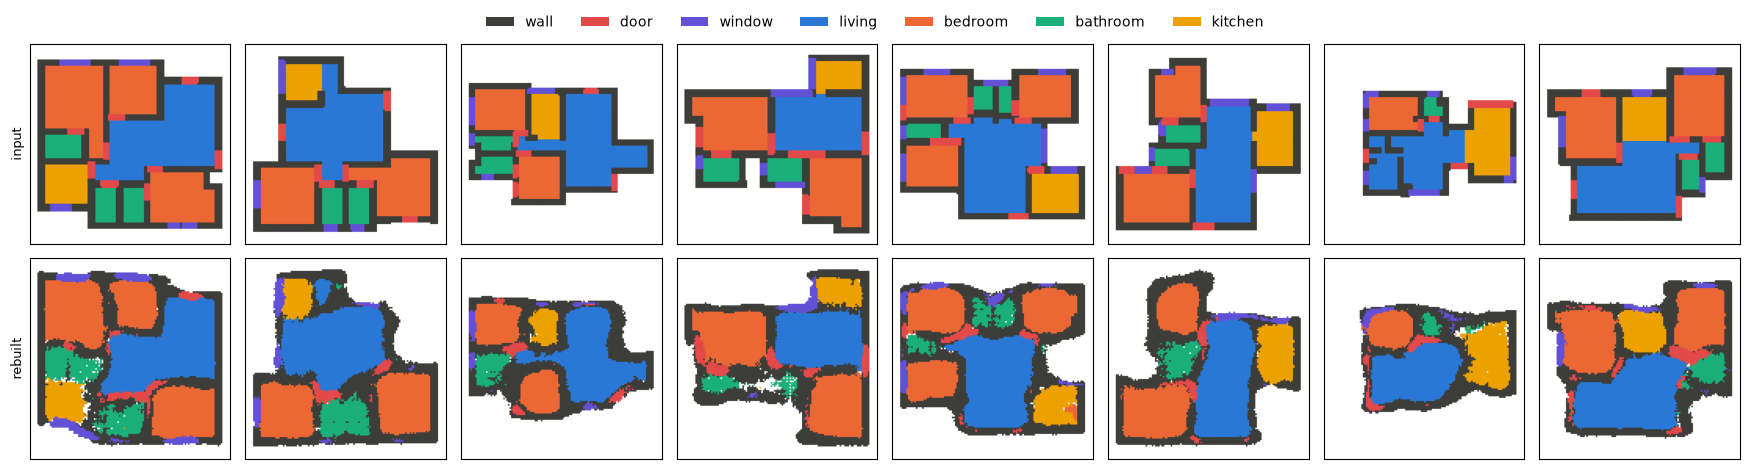

Figure saved to ..\figures\18_thin_layers.png


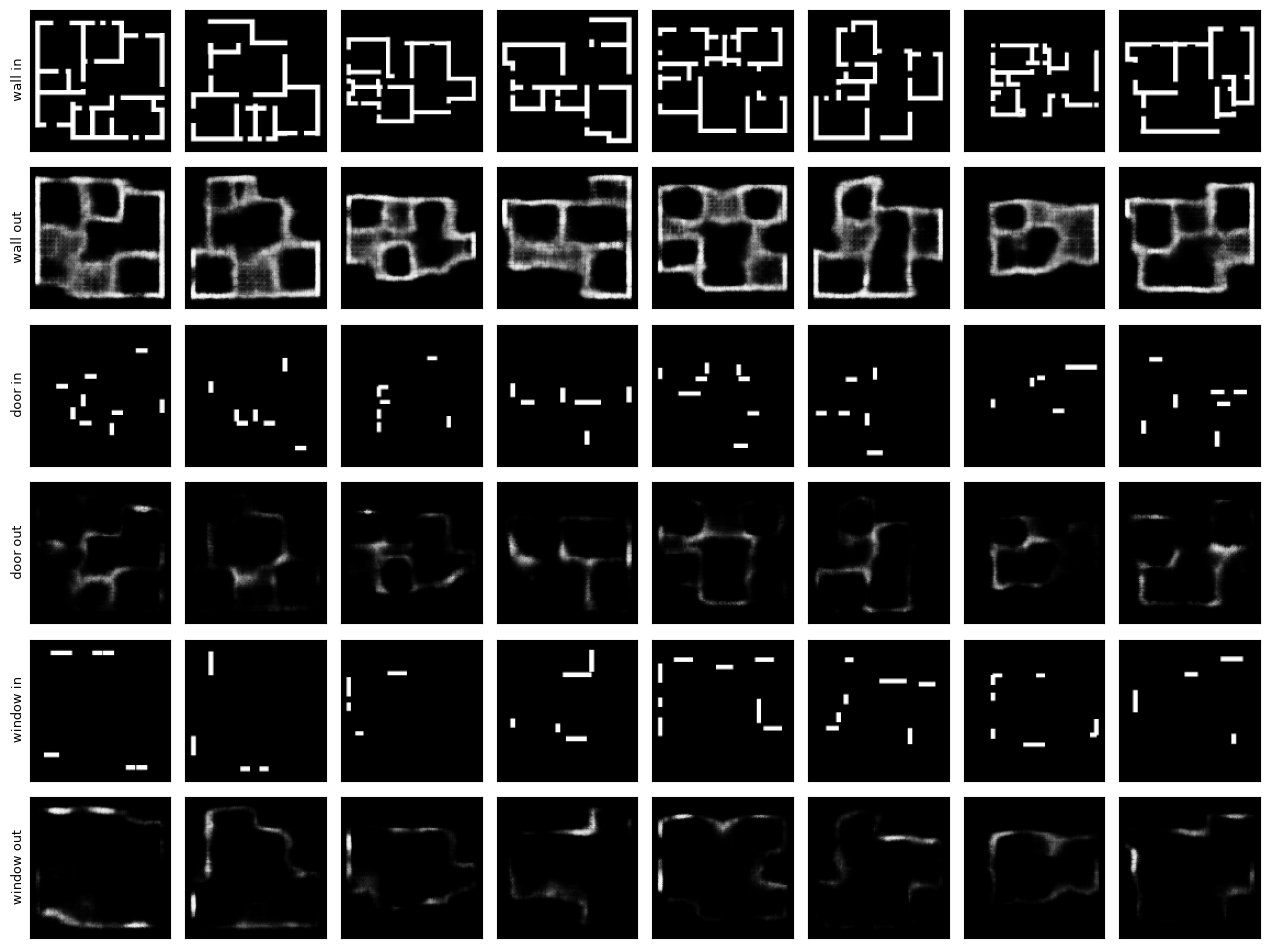

In [63]:
sample_r = R_val[:8]
rebuilt_r = reconstruct(room_ae, sample_r)
show_rooms([sample_r, rebuilt_r], ["input", "rebuilt"])
save_fig("17_layers_reconstructions")
plt.show()

rows, labels = [], []
for name in THIN_LAYERS:
    k = CHANNELS.index(name)
    rows += [sample_r[:, k:k + 1], rebuilt_r[:, k:k + 1]]
    labels += [f"{name} in", f"{name} out"]
show_images(rows, row_labels=labels, size=1.6)
save_fig("18_thin_layers")
plt.show()

10.6

In [64]:
@torch.no_grad()
def layer_iou(model, X):
    out = reconstruct(model, X)
    rows = []
    for k, c in enumerate(CHANNELS):
        t = 0.3 if c in THIN_LAYERS else 0.5
        true, pred = X[:, k] > t, out[:, k] > t
        inter, union = (true & pred).sum().item(), (true | pred).sum().item()
        rows.append({"layer": c, "IoU": inter / union if union else np.nan,
                     "share of pixels": true.float().mean().item()})
    return pd.DataFrame(rows).set_index("layer")


layer_iou(room_ae, R_val).round(3)

,IoU,share of pixels
layer,,
wall,0.5200,0.1420
door,0.2810,0.0210
window,0.3290,0.0250
living,0.8880,0.1720
bedroom,0.8840,0.1750
bathroom,0.6120,0.0470
kitchen,0.7390,0.0440


10.5

Figure saved to ..\figures\17_layers_reconstructions.png


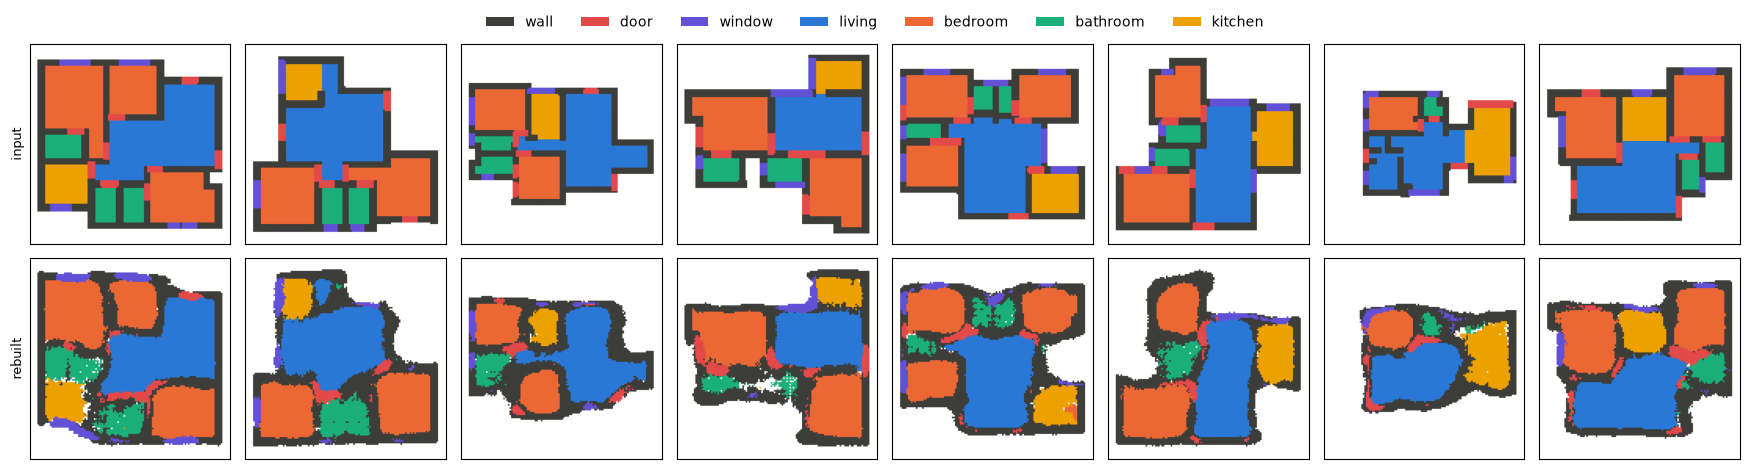

Figure saved to ..\figures\18_thin_layers.png


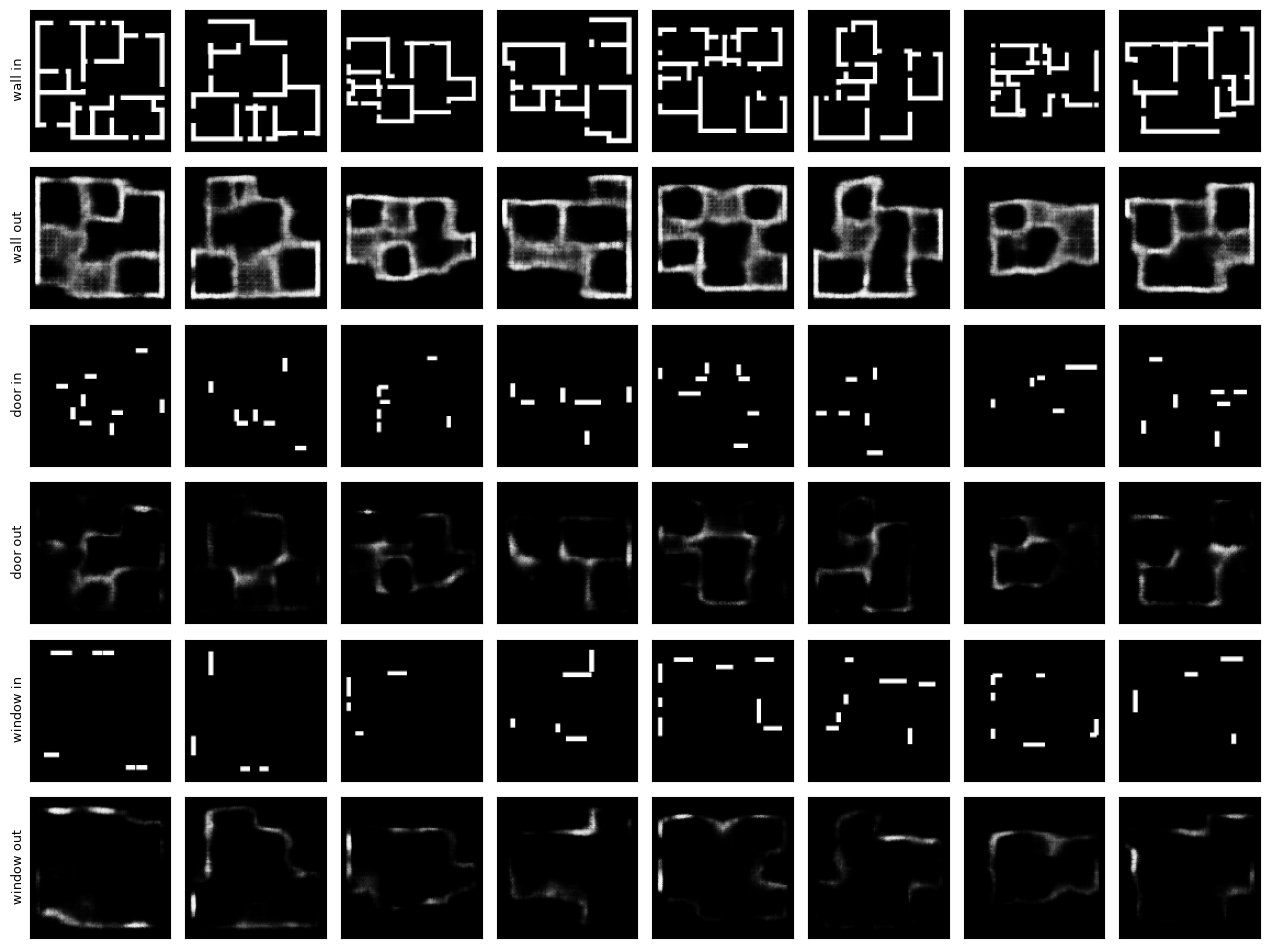

In [68]:
sample_r = R_val[:8]
rebuilt_r = reconstruct(room_ae, sample_r)
show_rooms([sample_r, rebuilt_r], ["input", "rebuilt"])
save_fig("17_layers_reconstructions")
plt.show()

rows, labels = [], []
for name in THIN_LAYERS:
    k = CHANNELS.index(name)
    rows += [sample_r[:, k:k + 1], rebuilt_r[:, k:k + 1]]
    labels += [f"{name} in", f"{name} out"]
show_images(rows, row_labels=labels, size=1.6)
save_fig("18_thin_layers")
plt.show()

10.6

In [69]:
@torch.no_grad()
def layer_iou(model, X):
    out = reconstruct(model, X)
    rows = []
    for k, c in enumerate(CHANNELS):
        t = 0.3 if c in THIN_LAYERS else 0.5
        true, pred = X[:, k] > t, out[:, k] > t
        inter, union = (true & pred).sum().item(), (true | pred).sum().item()
        rows.append({"layer": c, "IoU": inter / union if union else np.nan,
                     "share of pixels": true.float().mean().item()})
    return pd.DataFrame(rows).set_index("layer")


layer_iou(room_ae, R_val).round(3)

,IoU,share of pixels
layer,,
wall,0.5200,0.1420
door,0.2810,0.0210
window,0.3290,0.0250
living,0.8880,0.1720
bedroom,0.8840,0.1750
bathroom,0.6120,0.0470
kitchen,0.7390,0.0440


In [70]:
layer_iou(room_vae, R_val).round(3)

,IoU,share of pixels
layer,,
wall,0.3180,0.1420
door,0.0000,0.0210
window,0.2660,0.0250
living,0.7310,0.1720
bedroom,0.5030,0.1750
bathroom,0.0000,0.0470
kitchen,0.0000,0.0440


# 11. Generative design with a VAE, version 2 (rooms, walls, doors, windows)

The same idea as section 8, now on the **7-layer, 128 × 128** plans of section 10. The VAE can now try to generate a **room layout**, not only an outline.

Changes from section 8:
- the same layers as `RoomAE` (7 channels in and out, 128 → 8 and back);
- the weighted error of section 10 (walls 3×, doors and windows 8×);
- `BETA = 50` instead of 1: our images have about 28× more values than in section 8, so the reconstruction term would push the KL term aside and the latent space would not be smooth;
- two blends: **square → long**, and **1 bedroom → 3 bedrooms**.

In [65]:
class RoomVAE(nn.Module):
    def __init__(self, latent_dim=64, channels=len(CHANNELS)):
        super().__init__()
        self.latent_dim = latent_dim
        self.features = nn.Sequential(
            nn.Conv2d(channels, 32, 3, stride=2, padding=1), nn.ReLU(),   # 128 -> 64
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),         # 64 -> 32
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.ReLU(),        # 32 -> 16
            nn.Conv2d(128, 128, 3, stride=2, padding=1), nn.ReLU(),       # 16 -> 8
            nn.Flatten(),
        )
        self.to_mean = nn.Linear(128 * 8 * 8, latent_dim)
        self.to_logvar = nn.Linear(128 * 8 * 8, latent_dim)
        self.decoder = RoomAE(latent_dim).decoder           # the same decoder as RoomAE

    def encoder(self, x):
        if x.dtype == torch.uint8:
            x = x.float() / 255
        return self.to_mean(self.features(x))               # the mean code: used for blending and search

    def forward(self, x):
        if x.dtype == torch.uint8:                           # training images are stored as 0-255
            x = x.float() / 255
        h = self.features(x)
        mean, logvar = self.to_mean(h), self.to_logvar(h)
        z = mean + torch.randn_like(mean) * torch.exp(0.5 * logvar)   # sample a code from the cloud
        self.kl = -0.5 * torch.mean(torch.sum(1 + logvar - mean ** 2 - logvar.exp(), dim=1))
        return self.decoder(z)


BETA_ROOMS = 50.0


def room_vae_loss(output, target, model):
    if target.dtype == torch.uint8:
        target = target.float() / 255
    bce = nn.functional.binary_cross_entropy(output, target, reduction="none") * LAYER_WEIGHTS.to(output.device)
    reconstruction = bce.sum() / len(target)                # per plan, as in the class notebook
    return reconstruction + BETA_ROOMS * model.kl


room_vae, room_vae_hist = train_autoencoder(RoomVAE(latent_dim=64), R_train, R_val,
                                            epochs=10, loss_fn=room_vae_loss, verbose=True)

epoch  1  train loss 125673.0152  validation MSE 0.0709
epoch  2  train loss 64775.9955  validation MSE 0.0673
epoch  3  train loss 61833.4679  validation MSE 0.0665
epoch  4  train loss 60713.5921  validation MSE 0.0658
epoch  5  train loss 59582.9457  validation MSE 0.0648
epoch  6  train loss 58155.0913  validation MSE 0.0637
epoch  7  train loss 55737.4078  validation MSE 0.0605
epoch  8  train loss 52170.2077  validation MSE 0.0531
epoch  9  train loss 48538.6151  validation MSE 0.0463
epoch 10  train loss 45376.3519  validation MSE 0.0410
trained in 384 s


square → long: aspect 1.00 → 2.20
1 → 3 bedrooms: aspect 1.12 → 1.12
Figure saved to ..\figures\19_room_vae_generation.png


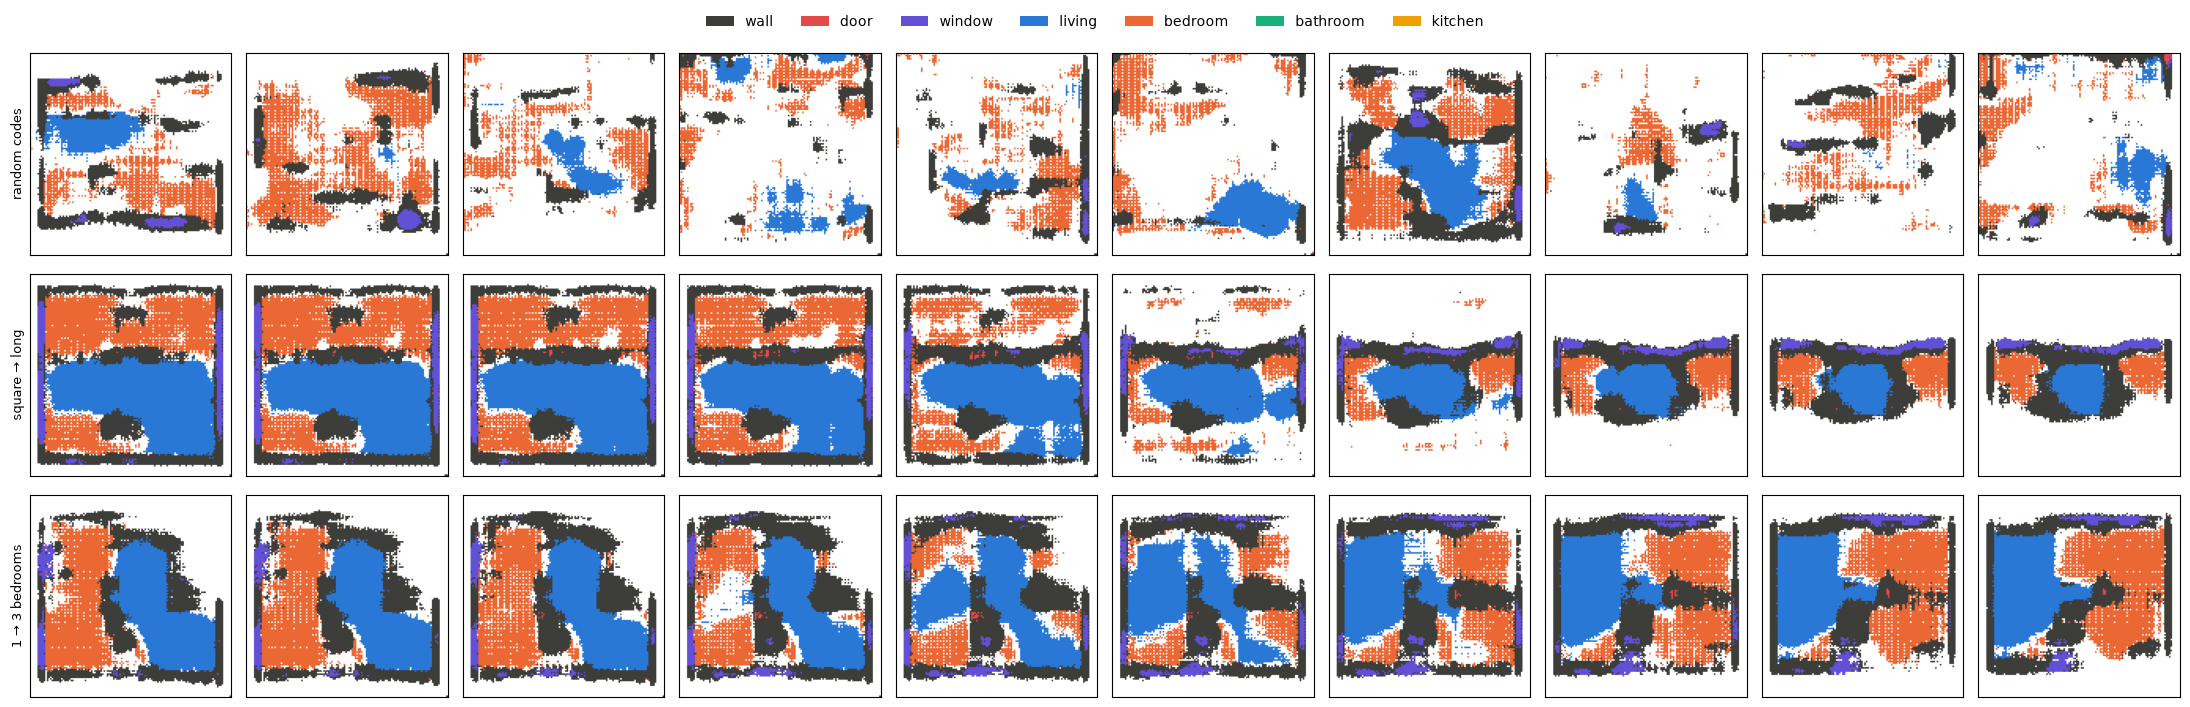

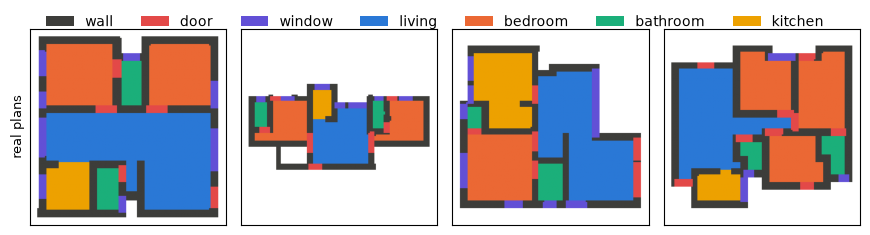

In [66]:
# 1) Brand-new plans from random codes
torch.manual_seed(RANDOM_STATE)
with torch.no_grad():
    room_vae.eval()
    generated_r = room_vae.decoder(torch.randn(10, room_vae.latent_dim, device=DEVICE)).cpu()


def blend_codes(model, a, b, steps=10):
    # walk in a straight line from the code of plan a to the code of plan b
    code_a, code_b = encode(model, R_test[a:a + 1]), encode(model, R_test[b:b + 1])
    t = torch.linspace(0, 1, steps).unsqueeze(1)
    with torch.no_grad():
        return model.decoder(((1 - t) * code_a + t * code_b).to(DEVICE)).cpu()


# 2) From the most square plan to a long, narrow one (aspect does not change when we turn a plan)
aspects = np.array([aspect_of(plans[i]) for i in test_idx])
i_square = int(np.argmin(np.abs(aspects - 1.0)))
i_long = int(np.argmin(np.abs(aspects - 2.2)))

# 3) From a 1-bedroom plan to a 3-bedroom plan with a similar shape
beds = np.array([len(get_geometries(plans[i].get("bedroom"))) for i in test_idx])
i_one = int(np.where(beds == 1)[0][0])
three = np.where(beds == 3)[0]
i_three = int(three[np.argmin(np.abs(aspects[three] - aspects[i_one]))])   # the 3-bedroom plan with the closest proportions
print(f"square → long: aspect {aspects[i_square]:.2f} → {aspects[i_long]:.2f}")
print(f"1 → 3 bedrooms: aspect {aspects[i_one]:.2f} → {aspects[i_three]:.2f}")

show_rooms([generated_r,
            blend_codes(room_vae, i_square, i_long),
            blend_codes(room_vae, i_one, i_three)],
           ["random codes", "square → long", "1 → 3 bedrooms"], n=10)
save_fig("19_room_vae_generation")
plt.show()

# The real start and end plans, to compare
show_rooms([R_test[[i_square, i_long, i_one, i_three]]], ["real plans"], n=4)
plt.show()

### What we conclude

- **Random codes:** most random codes still decode to scattered patches of rooms and wall pieces; only a few look like a plan. The latent space is not smooth enough yet: `BETA` is probably still too low.
- **Square → long:** a clear improvement over section 8. The decoded square plan matches the real one: bedrooms at the top, living room in the middle, outer walls around, and **windows on the outer walls**. Along the blend the plan gets longer and lower, and the layout is kept (living room in the centre, bedrooms at the sides).
- **1 → 3 bedrooms:** the bedroom area (orange) **grows and splits into separate rooms with a wall between them**, step by step. The end looks like the real 3-bedroom plan (living room on the left, bedrooms on the right). This is generative design at the level of the room layout, not only the outline.
- **What is missing:** the generated plans have no bathrooms or kitchens and no doors. The model learned the two **largest** room types (living room and bedroom) and the outer walls, but small elements are lost. In the 1-bedroom plan, the real kitchen is decoded as a bedroom.
- **Next steps:** a larger `BETA` (e.g. 200) for better random plans, higher weights for bathrooms and kitchens, and more epochs.

In [67]:
torch.save(room_ae.state_dict(), MODEL_DIR / "room_ae.pt")
print("saved room_ae")

saved room_ae


# 12. Version 3: cleaner data, balcony, and a loss for small elements

What we learned from version 2:
- the validation error was **still going down** after 20 epochs (about 5% per epoch): the model had not finished learning;
- the model learned the **rules** (doors and windows sit on walls, windows on outer walls) but not the **exact positions**: it spreads a faint door along every wall.

Changes in version 3:

| Change | Why |
|---|---|
| Apply the data cleaning (remove twins and leakage) | 33 val/test plans had a twin in train |
| Add a **balcony** layer (8 layers) | 77% of the plans have a balcony |
| **BCE + Dice loss** | Dice gives every layer the same weight, however small (doors and windows are 2% of the pixels) |
| Decoder with **upsample + conv** instead of `ConvTranspose2d` | removes the chequerboard "dots" inside the rooms |
| **256**-number code | exact positions of doors and windows need more room in the code |
| **60 epochs** (2 × 30) | version 2 was still improving at epoch 20 |
| Score with a **1-pixel tolerance** | IoU is very strict for thin lines |

In [72]:
# Step 1.2c (it was missing): keep ONE copy of each flat; train comes first, so val/test twins of train plans go
order = originals.assign(rank=originals["split"].map({"train": 0, "val": 1, "test": 2})).sort_values(["rank", "index"])
redundant = order.index[order.duplicated("fingerprint", keep="first")]
flag(table.index.isin(redundant), "duplicate (twin of another plan)")

keep = set(table.loc[table["remove_reason"] == "", "index"])
train_c = [i for i in train_idx if i in keep]
val_c = [i for i in val_idx if i in keep]
test_c = [i for i in test_idx if i in keep]
print(f"clean plans: train {len(train_c):,} | val {len(val_c):,} | test {len(test_c):,}")
print(table["remove_reason"].value_counts())

# Free the memory of version 2 (its results are already in the notebook, and the weights are saved)
for name in ["R_train", "R_val", "R_test", "R_train_u8", "R_val_u8", "R_test_u8"]:
    globals().pop(name, None)

duplicate (twin of another plan)                 111 plans flagged
clean plans: train 12,983 | val 1,612 | test 1,611
remove_reason
                                    16206
augmented copy                        683
duplicate (twin of another plan)      111
Name: count, dtype: int64


12.2

In [74]:
CHANNELS3 = ["wall", "door", "window", "living", "bedroom", "bathroom", "kitchen", "balcony"]
THIN3 = ["wall", "door", "window"]
ROOMS3 = CHANNELS3[3:]


def plan_to_layers(plan, size=128, draw_size=512, margin=MARGIN):
    layers = {c: get_geometries(plan.get(c)) for c in CHANNELS3}
    layers["door"] = layers["door"] + get_geometries(plan.get("front_door"))   # the entrance is a door too
    outline = get_geometries(plan.get("inner")) + layers["wall"]
    if not outline:
        return np.zeros((len(CHANNELS3), size, size), dtype=np.float32)

    minx, miny, maxx, maxy = bounds_of(outline)
    if (maxy - miny) > (maxx - minx):              # turn "standing" plans so the long side is horizontal
        layers = {c: rotate_90(g) for c, g in layers.items()}
        outline = rotate_90(outline)
        minx, miny, maxx, maxy = bounds_of(outline)

    w, h = maxx - minx, maxy - miny
    scale = draw_size * (1 - 2 * margin) / max(w, h)
    xoff = (draw_size - w * scale) / 2 - minx * scale
    yoff = (draw_size + h * scale) / 2 + miny * scale

    out = np.zeros((len(CHANNELS3), size, size), dtype=np.float32)
    for k, c in enumerate(CHANNELS3):
        geoms = [affinity.affine_transform(g, [scale, 0, 0, -scale, xoff, yoff]) for g in layers[c]]
        mask = geometry_to_mask(geoms, shape=(draw_size, draw_size))
        if c in THIN3:
            mask = cv2.dilate(mask, np.ones((3, 3), np.uint8), iterations=THICKEN)
        out[k] = cv2.resize(mask.astype(np.float32) / 255.0, (size, size), interpolation=cv2.INTER_AREA)
    return out


CACHE_V3 = DATA_DIR / "resplan_8layers_128px_clean.npz"
if CACHE_V3.exists():
    cached = np.load(CACHE_V3)
    P_train_u8, P_val_u8, P_test_u8 = cached["train"], cached["val"], cached["test"]
    print(f"loaded from {CACHE_V3}")
else:
    start = time.time()
    make = lambda idx: np.stack([(plan_to_layers(plans[i]) * 255).round().astype(np.uint8) for i in idx])
    P_train_u8, P_val_u8, P_test_u8 = make(train_c), make(val_c), make(test_c)
    np.savez_compressed(CACHE_V3, train=P_train_u8, val=P_val_u8, test=P_test_u8)
    print(f"drew the plans in {time.time() - start:.0f} s, saved to {CACHE_V3}")

P_train = torch.from_numpy(P_train_u8)             # 0-255, small; the model converts it
P_val = torch.from_numpy(P_val_u8).float() / 255   # 0-1, for the validation error and the figures
print("train", tuple(P_train.shape), "| validation", tuple(P_val.shape), "| test", P_test_u8.shape)

drew the plans in 144 s, saved to ..\..\data\resplan_8layers_128px_clean.npz
train (12983, 8, 128, 128) | validation (1612, 8, 128, 128) | test (1611, 8, 128, 128)


12.3

Figure saved to ..\figures\20_v3_input.png


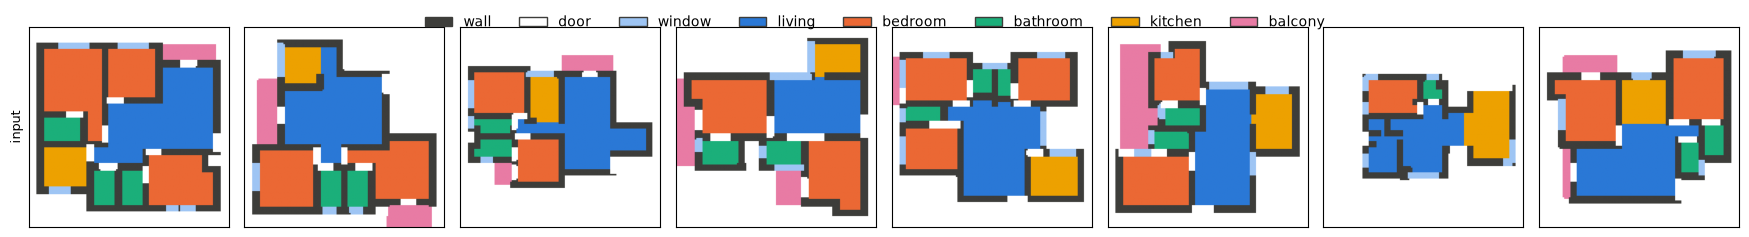

In [75]:
COLORS3 = {"wall": "#3d3d3a", "door": "#ffffff", "window": "#9ec5f4",
           "living": "#2a78d6", "bedroom": "#eb6834", "bathroom": "#1baf7a", "kitchen": "#eda100", "balcony": "#e87ba4"}


def to_color3(x, thin_threshold=0.3, room_threshold=0.5):
    x = x.detach().cpu().float().numpy() if torch.is_tensor(x) else x
    rgb = np.ones((x.shape[1], x.shape[2], 3))
    room_idx, room_val = x[3:].argmax(0), x[3:].max(0)
    for k, name in enumerate(ROOMS3):
        rgb[(room_idx == k) & (room_val > room_threshold)] = to_rgb(COLORS3[name])
    for name in ["wall", "window", "door"]:                     # doors last: white openings in the walls
        rgb[x[CHANNELS3.index(name)] > thin_threshold] = to_rgb(COLORS3[name])
    return rgb


def show_layers(rows, row_labels, n=8):
    fig, axes = plt.subplots(len(rows), n, figsize=(2.2 * n, 2.3 * len(rows)), squeeze=False)
    for r, batch in enumerate(rows):
        for c in range(n):
            axes[r, c].imshow(to_color3(batch[c]))
            axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        axes[r, 0].set_ylabel(row_labels[r], fontsize=9)
    fig.legend(handles=[Patch(facecolor=COLORS3[c], edgecolor="#3d3d3a", label=c) for c in CHANNELS3],
               loc="upper center", ncol=len(CHANNELS3), frameon=False, bbox_to_anchor=(0.5, 1.04))
    plt.tight_layout()


show_layers([P_val[:8]], ["input"])
save_fig("20_v3_input")
plt.show()

12.4

In [76]:
def up(cin, cout):
    # double the size, then a normal convolution: avoids the chequerboard dots of ConvTranspose2d
    return nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"), nn.Conv2d(cin, cout, 3, padding=1), nn.ReLU())


class PlanAE(nn.Module):
    def __init__(self, latent_dim=256, channels=len(CHANNELS3)):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(channels, 32, 3, stride=2, padding=1), nn.ReLU(),   # 128 -> 64
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),         # 64 -> 32
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.ReLU(),        # 32 -> 16
            nn.Conv2d(128, 128, 3, stride=2, padding=1), nn.ReLU(),       # 16 -> 8
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, latent_dim),                           # the code
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128 * 8 * 8), nn.ReLU(),
            nn.Unflatten(1, (128, 8, 8)),
            up(128, 128),                                                 # 8 -> 16
            up(128, 64),                                                  # 16 -> 32
            up(64, 32),                                                   # 32 -> 64
            nn.Upsample(scale_factor=2, mode="nearest"),                  # 64 -> 128
            nn.Conv2d(32, channels, 3, padding=1), nn.Sigmoid(),
        )

    def forward(self, x):
        if x.dtype == torch.uint8:
            x = x.float() / 255
        return self.decoder(self.encoder(x))


#                         wall door window living bedroom bathroom kitchen balcony
WEIGHTS3 = torch.tensor([3.0, 8.0, 8.0,   1.0,   1.0,    2.0,     2.0,    2.0]).view(1, -1, 1, 1)
DICE_WEIGHT = 1.0


def bce_dice_loss(output, target, model):
    if target.dtype == torch.uint8:
        target = target.float() / 255
    bce = (nn.functional.binary_cross_entropy(output, target, reduction="none") * WEIGHTS3.to(output.device)).mean()
    # Dice: overlap between output and target, per plan and per layer (every layer counts the same, however small)
    inter = (output * target).sum(dim=(2, 3))
    total = output.sum(dim=(2, 3)) + target.sum(dim=(2, 3))
    dice = 1 - (2 * inter + 1) / (total + 1)                 # +1: no division by zero when a layer is empty
    return bce + DICE_WEIGHT * dice.mean()


out = PlanAE()(torch.zeros(2, len(CHANNELS3), 128, 128))
print(f"PlanAE: output {tuple(out.shape)}, {n_params(PlanAE()):,} parameters")

PlanAE: output (2, 8, 128, 128), 4,687,176 parameters


12.5

In [77]:
plan_ae, hist_a = train_autoencoder(PlanAE(latent_dim=256), P_train, P_val,
                                    epochs=30, loss_fn=bce_dice_loss, verbose=True)
torch.save(plan_ae.state_dict(), MODEL_DIR / "plan_ae_v3.pt")

epoch  1  train loss 1.7093  validation MSE 0.0622
epoch  2  train loss 1.3909  validation MSE 0.0598
epoch  3  train loss 1.3331  validation MSE 0.0577
epoch  4  train loss 1.2667  validation MSE 0.0536
epoch  5  train loss 1.1511  validation MSE 0.0427
epoch  6  train loss 1.0307  validation MSE 0.0347
epoch  7  train loss 0.9110  validation MSE 0.0295
epoch  8  train loss 0.8074  validation MSE 0.0257
epoch  9  train loss 0.7350  validation MSE 0.0233
epoch 10  train loss 0.6724  validation MSE 0.0219
epoch 11  train loss 0.6179  validation MSE 0.0198
epoch 12  train loss 0.5791  validation MSE 0.0186
epoch 13  train loss 0.5537  validation MSE 0.0184
epoch 14  train loss 0.5336  validation MSE 0.0173
epoch 15  train loss 0.5107  validation MSE 0.0167
epoch 16  train loss 0.4908  validation MSE 0.0162
epoch 17  train loss 0.4732  validation MSE 0.0159
epoch 18  train loss 0.4578  validation MSE 0.0154
epoch 19  train loss 0.4458  validation MSE 0.0150
epoch 20  train loss 0.4264  va

12.6

In [78]:
plan_ae, hist_b = train_autoencoder(plan_ae, P_train, P_val, epochs=30, loss_fn=bce_dice_loss, verbose=True)
torch.save(plan_ae.state_dict(), MODEL_DIR / "plan_ae_v3.pt")
plan_hist = pd.concat([hist_a, hist_b.assign(epoch=hist_b["epoch"] + len(hist_a))], ignore_index=True)

epoch  1  train loss 0.6039  validation MSE 0.0136
epoch  2  train loss 0.3488  validation MSE 0.0124
epoch  3  train loss 0.3284  validation MSE 0.0123
epoch  4  train loss 0.3169  validation MSE 0.0121
epoch  5  train loss 0.3113  validation MSE 0.0121
epoch  6  train loss 0.3074  validation MSE 0.0120
epoch  7  train loss 0.3041  validation MSE 0.0121
epoch  8  train loss 0.2988  validation MSE 0.0120
epoch  9  train loss 0.2944  validation MSE 0.0118
epoch 10  train loss 0.2917  validation MSE 0.0118
epoch 11  train loss 0.2865  validation MSE 0.0119
epoch 12  train loss 0.2834  validation MSE 0.0116
epoch 13  train loss 0.2813  validation MSE 0.0116
epoch 14  train loss 0.2759  validation MSE 0.0118
epoch 15  train loss 0.2740  validation MSE 0.0114
epoch 16  train loss 0.2689  validation MSE 0.0116
epoch 17  train loss 0.2645  validation MSE 0.0115
epoch 18  train loss 0.2624  validation MSE 0.0114
epoch 19  train loss 0.2612  validation MSE 0.0113
epoch 20  train loss 0.2556  va

12.7

Figure saved to ..\figures\21_v3_reconstructions.png


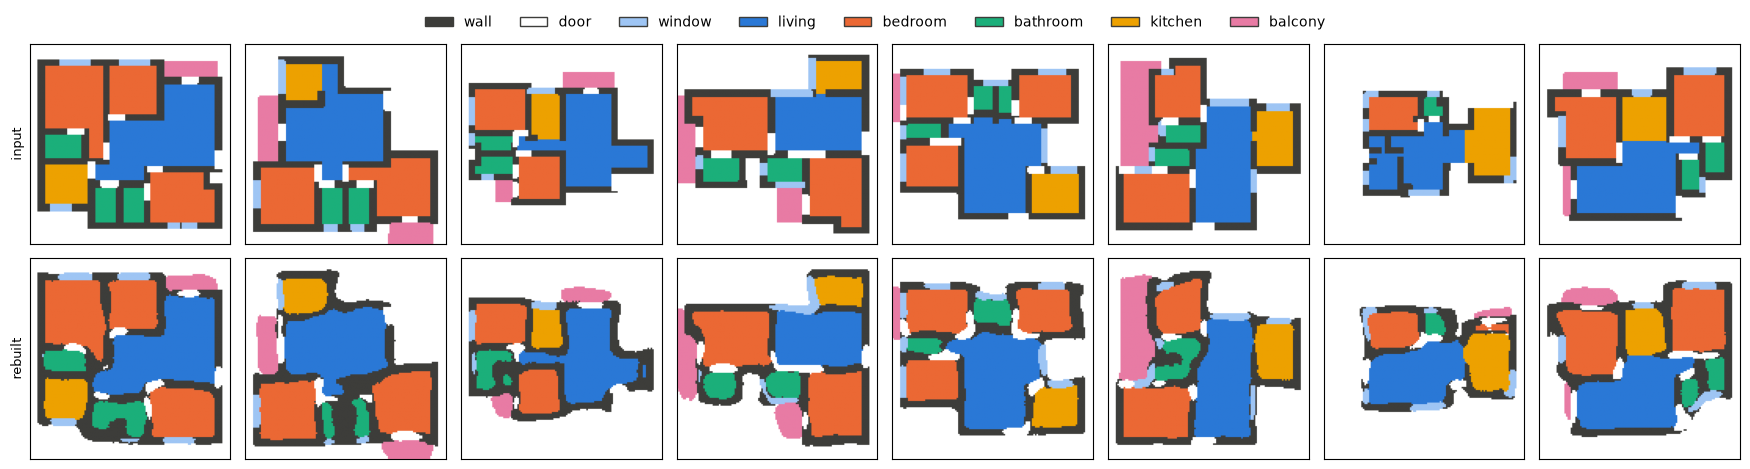

Figure saved to ..\figures\22_v3_thin_layers.png


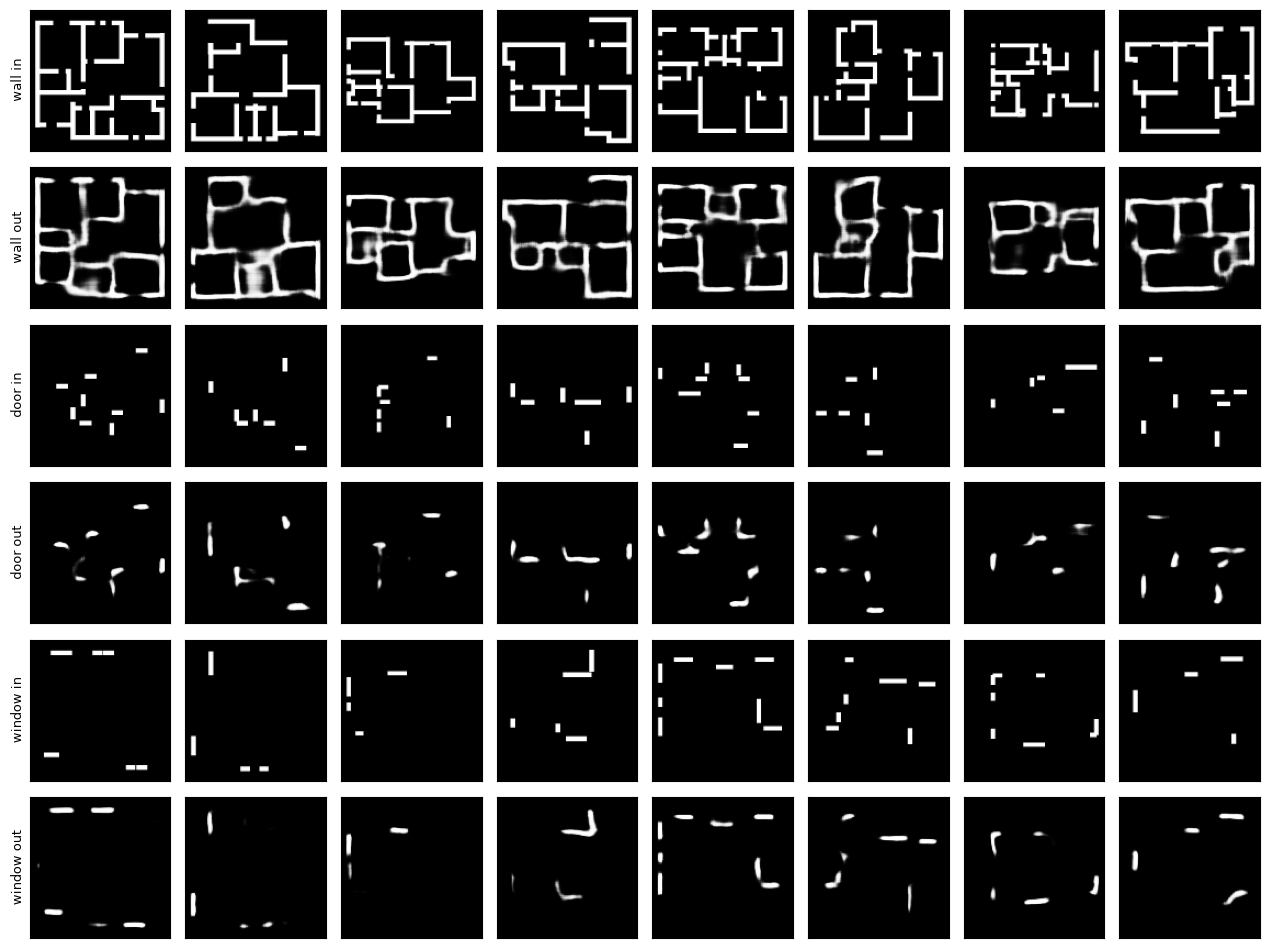

,IoU,F1 (1-pixel tolerance),share of pixels
layer,,,
wall,0.6410,0.9140,0.1420
door,0.4930,0.8360,0.0210
window,0.5520,0.8560,0.0250
living,0.9170,0.9840,0.1720
bedroom,0.9260,0.9900,0.1760
bathroom,0.8240,0.9700,0.0470
kitchen,0.8750,0.9770,0.0450
balcony,0.7880,0.9490,0.0280


In [79]:
import torch.nn.functional as F

sample_p = P_val[:8]
rebuilt_p = reconstruct(plan_ae, sample_p)
show_layers([sample_p, rebuilt_p], ["input", "rebuilt"])
save_fig("21_v3_reconstructions")
plt.show()

rows, labels = [], []
for name in THIN3:
    k = CHANNELS3.index(name)
    rows += [sample_p[:, k:k + 1], rebuilt_p[:, k:k + 1]]
    labels += [f"{name} in", f"{name} out"]
show_images(rows, row_labels=labels, size=1.6)
save_fig("22_v3_thin_layers")
plt.show()


@torch.no_grad()
def layer_scores(model, X):
    out = reconstruct(model, X)
    grow = lambda m: F.max_pool2d(m[:, None].float(), 3, stride=1, padding=1)[:, 0] > 0   # widen by 1 pixel
    rows = []
    for k, c in enumerate(CHANNELS3):
        t = 0.3 if c in THIN3 else 0.5
        true, pred = X[:, k] > t, out[:, k] > t
        inter, union = (true & pred).sum().item(), (true | pred).sum().item()
        # with a 1-pixel tolerance: a wall drawn one pixel off still counts
        precision = (pred & grow(true)).sum().item() / max(pred.sum().item(), 1)
        recall = (true & grow(pred)).sum().item() / max(true.sum().item(), 1)
        rows.append({"layer": c, "IoU": inter / union if union else np.nan,
                     "F1 (1-pixel tolerance)": 2 * precision * recall / max(precision + recall, 1e-9),
                     "share of pixels": true.float().mean().item()})
    return pd.DataFrame(rows).set_index("layer")


layer_scores(plan_ae, P_val).round(3)

### What we conclude (version 3, validation set)

| layer | IoU v2 | IoU v3 | F1 v3 (1-pixel tolerance) |
|---|---|---|---|
| wall | 0.52 | 0.64 | 0.91 |
| door | 0.28 | 0.49 | 0.84 |
| window | 0.33 | 0.55 | 0.86 |
| living | 0.89 | 0.92 | 0.98 |
| bedroom | 0.88 | 0.93 | 0.99 |
| bathroom | 0.61 | 0.82 | 0.97 |
| kitchen | 0.74 | 0.88 | 0.98 |
| balcony | – | 0.79 | 0.95 |

- **Every layer improved**, most of all the small ones: doors +75%, windows +68%, bathrooms +35%.
- **With a 1-pixel tolerance, the thin elements are almost right:** walls 0.91, windows 0.86, doors 0.84. The model places them in the right spot, usually at most one pixel off; the plain IoU punishes that small shift.
- **In the images** the room layout is almost identical to the input in all 8 plans. Doors appear as openings in the walls, windows sit on the outer walls, balconies are rebuilt, and the chequerboard dots of version 2 are gone (upsample + conv decoder).
- **Still not perfect:** rounded corners and rough wall edges, small neighbouring rooms (e.g. two bathrooms) merge, and complex plans with many small rooms are simplified.
- **Limit of this comparison:** we changed several things at once (Dice loss, decoder, 256-number code, 60 epochs, cleaned data), so we cannot say which change helped most. The validation set is also slightly smaller after cleaning.